In [2]:
# 0. Setup and filters

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import entropy

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

# --- Добавляем корень репо в sys.path, чтобы работал импорт src.* ---
_root = Path.cwd()
while not (_root / 'src').is_dir() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.paths import get_base_path

# --- Загрузка данных ---
BASE_PATH = get_base_path()
df = pd.read_parquet(BASE_PATH / 'eda_ready.parquet')

# --- Паспорт данных ---
# Печатаем только агрегаты: период, число аккаунтов, число треков.
# Имена аккаунтов не выводим — приватность.
print(f'📦 Events loaded: {len(df)}')
print(f'📅 Period: {df["ts"].min().date()} — {df["ts"].max().date()}')
print(f'👥 Accounts: {df["account"].nunique()}')
print(f'🎵 Unique tracks: {df["spotify_track_uri"].nunique()}')

# Пропуски в ключевых полях — важно понимать до расчёта фильтров,
# потому что popularity и tempo имеют технические NaN (заменены на 0 в 00_1).
key_cols = ['valence', 'energy', 'danceability', 'tempo', 'popularity', 'genres', 'played_frac']
print('\n📋 Missing values in key fields:')
print(df[key_cols].isnull().sum())

# --- Валидное прослушивание (valid_play) ---
# Условия: не скип, не короче 30 секунд, не техническая причина завершения,
# прослушано не менее 50% длительности трека.
# Это отделяет осознанное прослушивание от фонового и технического.
exclude_reasons = ['trackerror', 'fwdbtn', 'backbtn', 'logout', 'remote', 'unexpected-exit']

df['valid_play'] = (
    (~df['is_skip']) &
    (df['ms_played'] >= 30_000) &
    (~df['reason_end'].isin(exclude_reasons)) &
    (df['played_frac'] >= 0.5)
)

# --- Количество валидных прослушиваний на трек ---
# Считаем один раз, дальше используем для масок Core ≥3 и Core ≥5.
valid_count_map = df[df['valid_play']].groupby('spotify_track_uri').size()
df['valid_listen_count'] = df['spotify_track_uri'].map(valid_count_map).fillna(0).astype(int)

# --- Финальные маски ---
# Пять фильтров, вложенных по смыслу:
#   All events  → весь поток, включая шум
#   No skips    → без мгновенных скипов
#   Core ≥3     → треки, валидно прослушанные ≥3 раз
#   Core ≥5     → треки, валидно прослушанные ≥5 раз
#   Deep dive   → ядро ≥5 ИЛИ высокая доля прослушивания (≥0.7)
mask_all     = np.ones(len(df), dtype=bool)
mask_no_skip = ~df['is_skip']
mask_core3   = df['valid_play'] & (df['valid_listen_count'] >= 3)
mask_core5   = df['valid_play'] & (df['valid_listen_count'] >= 5)
mask_deep    = df['valid_play'] & ((df['valid_listen_count'] >= 5) | (df['played_frac'] >= 0.7))

filters = {
    'All events':      mask_all,
    'No skips':        mask_no_skip,
    'Core ≥3 (valid)': mask_core3,
    'Core ≥5 (valid)': mask_core5,
    'Deep dive':       mask_deep,
}

print('\n📊 Filter sizes:')
for name, mask in filters.items():
    print(f'   {name}: {mask.sum()} events ({mask.sum()/len(df)*100:.1f}%)')


def show_unknown_share(data: pd.DataFrame, group_name: str) -> float:
    """
    Доля событий с неизвестным жанром.

    Учитываем только 'unknown' — кириллица без перевода уже
    преобразована в 'unknown' на этапе 00_1.
    Если доля >30% — предупреждение, если >50% — жанровые выводы делать нельзя.
    """
    if 'genres_normalized' not in data.columns:
        print(f'ℹ️ {group_name}: no genre data.')
        return 0.0

    total = len(data)
    if total == 0:
        return 0.0

    mask = (data['genres_normalized'] == 'unknown')
    share = mask.mean() * 100

    if share > 50:
        print(f'🚨 {group_name}: {share:.1f}% tracks without genre — genre conclusions unreliable.')
    elif share > 30:
        print(f'⚠️ {group_name}: {share:.1f}% tracks without genre — genre conclusions limited.')
    else:
        print(f'ℹ️ {group_name}: {share:.1f}% tracks without genre.')

    return share

📦 Events loaded: 79752
📅 Period: 2020-05-18 — 2026-08-03
👥 Accounts: 3
🎵 Unique tracks: 25624

📋 Missing values in key fields:
valence             7
energy              7
danceability        7
tempo              58
popularity      17206
genres              0
played_frac         0
dtype: int64

📊 Filter sizes:
   All events: 79752 events (100.0%)
   No skips: 51745 events (64.9%)
   Core ≥3 (valid): 32058 events (40.2%)
   Core ≥5 (valid): 26102 events (32.7%)
   Deep dive: 45620 events (57.2%)


In [6]:
# 1. Масштаб и общая активность

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Проверка, что блок 0 выполнен
if 'filters' not in globals():
    raise ValueError('Переменная filters не найдена. Сначала выполните блок 0.')

# --- Масштаб по каждому фильтру ---
# Для каждого фильтра считаем: события, уникальные треки, артисты, альбомы,
# суммарное время в часах и число музыкальных дней.
# Музыкальный день — календарный день, в котором было хотя бы одно событие.
rows = []
for name, mask in filters.items():
    data = df[mask]
    total_events = len(data)
    unique_tracks = data['spotify_track_uri'].nunique()
    unique_artists = data['artist_name'].nunique()
    unique_albums = data['album_name'].nunique()
    total_hours = data['ms_played'].sum() / 3600000
    musical_days = pd.Series(pd.to_datetime(data['ts']).dt.date).nunique()

    rows.append({
        'Filter': name,
        'Events': total_events,
        'Unique tracks': unique_tracks,
        'Unique artists': unique_artists,
        'Unique albums': unique_albums,
        'Total hours': round(total_hours, 1),
        'Musical days': musical_days,
    })

scale_df = pd.DataFrame(rows)
scale_df.index = range(1, len(scale_df) + 1)
scale_df.index.name = '№'
print('📊 Scale by filter:')
display(scale_df)

# --- Средняя дневная и недельная активность (по всем событиям) ---
# Считаем по All events, потому что нам нужен полный поток,
# а не только осознанное ядро. Это даёт реальный ритм пользователя.
data = df.copy()
data['date'] = pd.to_datetime(data['ts']).dt.date
daily_events = data.groupby('date')['ts'].count()
weekly_events = pd.to_datetime(data['ts']).dt.tz_localize(None).dt.to_period('W').value_counts().sort_index()

print('\n📊 Activity (All events):')
print(f'   Mean events per day: {daily_events.mean():.1f}')
print(f'   Median events per day: {daily_events.median():.1f}')
print(f'   Mean events per week: {weekly_events.mean():.1f}')
print(f'   Median events per week: {weekly_events.median():.1f}')

# --- Медиана по всем календарным дням vs только по музыкальным ---
# Разница между этими двумя медианами показывает, как часто пользователь
# вообще включает музыку: если календарная медиана сильно ниже музыкальной,
# значит, много дней без музыки, и это влияет на «типичный день».
full_dates = pd.date_range(
    start=pd.to_datetime(data['ts']).min().date(),
    end=pd.to_datetime(data['ts']).max().date(),
    freq='D'
)
all_days_counts = pd.Series(0, index=full_dates)
all_days_counts = all_days_counts.add(data.groupby(data['date'])['ts'].count(), fill_value=0)

median_all_days = all_days_counts.median()
median_music_days = daily_events.median()

print('\n📊 Median events:')
print(f'   Across all calendar days: {median_all_days:.1f}')
print(f'   Only on musical days: {median_music_days:.1f}')
print(f'   Share of musical days: {(all_days_counts > 0).mean()*100:.1f}%')

📊 Scale by filter:


,Filter,Events,Unique tracks,Unique artists,Unique albums,Total hours,Musical days
№,,,,,,,
1,All events,79752,25624,9548,16340,3350.8,1364
2,No skips,51745,17328,6591,11406,3192.0,1324
3,Core ≥3 (valid),32058,4158,1683,2942,2143.0,1127
4,Core ≥5 (valid),26102,2381,1109,1783,1741.1,1083
5,Deep dive,45620,15273,5809,10046,3066.5,1189



📊 Activity (All events):
   Mean events per day: 58.5
   Median events per day: 32.5
   Mean events per week: 267.6
   Median events per week: 181.5

📊 Median events:
   Across all calendar days: 7.0
   Only on musical days: 32.5
   Share of musical days: 60.1%


In [ ]:
# 2. Access context: online/offline


# Это статичный контекст доступа, он не относится к временной динамике
# (она разобрана в этапе 2, блок 7 — «Платформы во времени»).

print('\n📊 Access context\n')

offline_counts = df['offline'].value_counts()
offline_pct = (offline_counts / len(df) * 100).round(1)

print('Offline vs online:')
for val, cnt in offline_counts.items():
    label = 'Offline' if val else 'Online'
    print(f'   {label}: {cnt} ({offline_pct[val]}%)')


📊 Access context

Offline vs online:
   Online: 79091 (99.2%)
   Offline: 661 (0.8%)


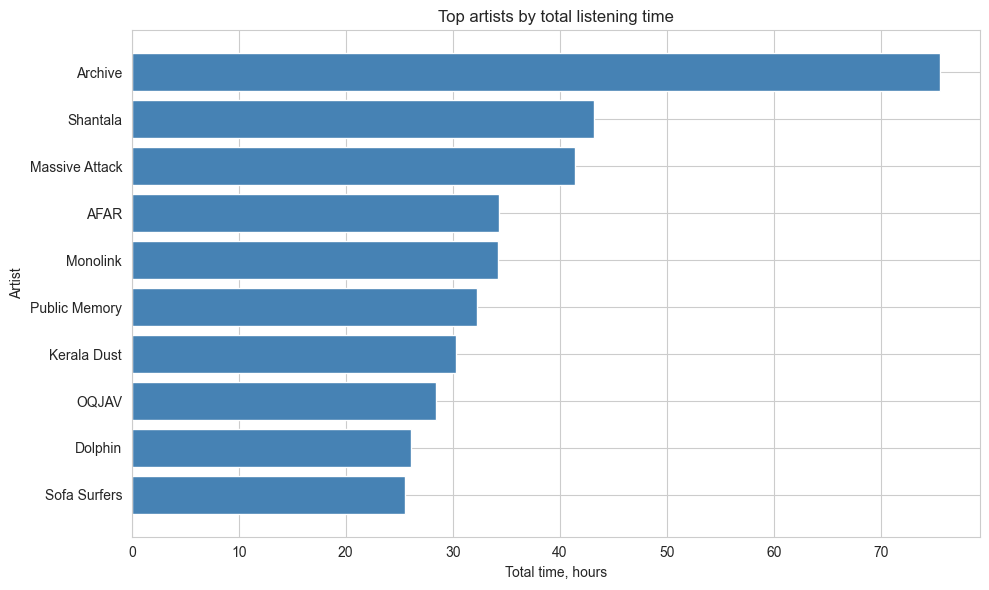

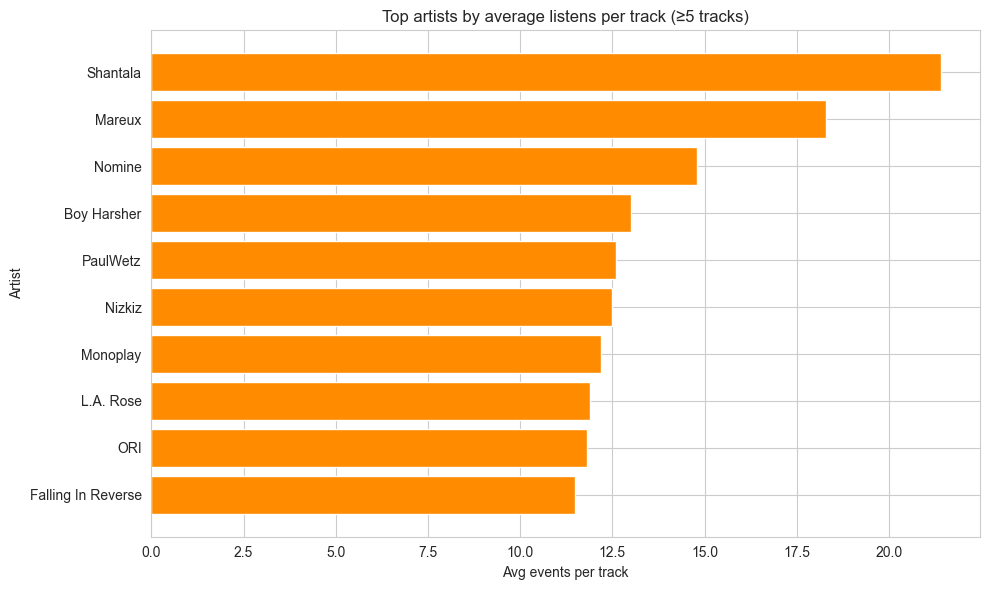

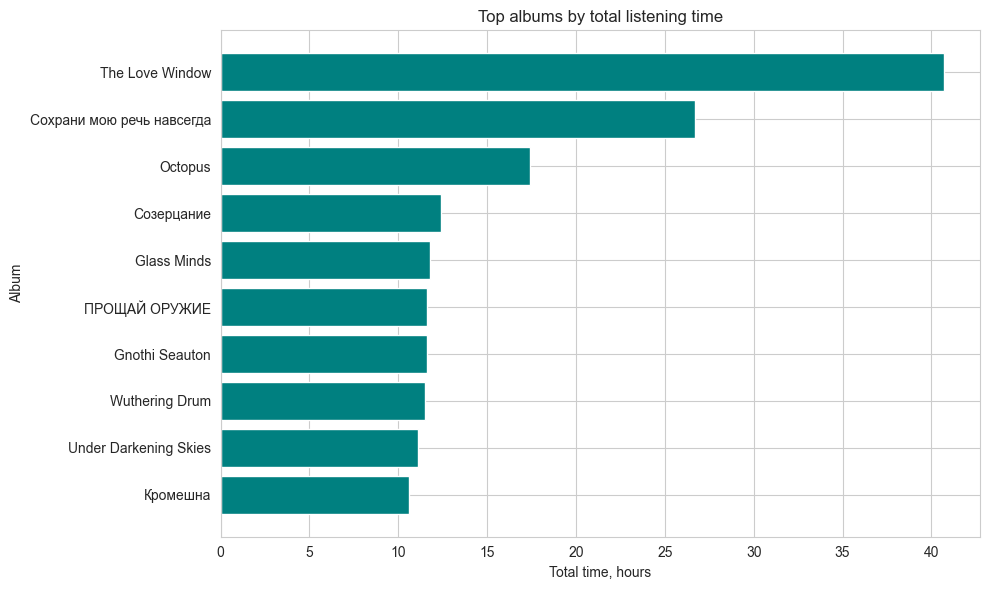

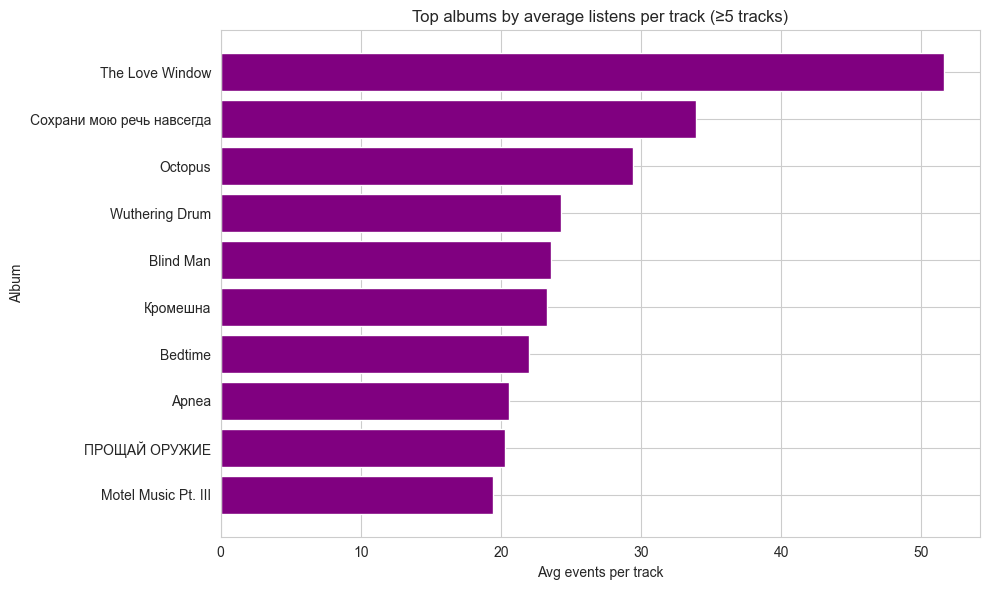

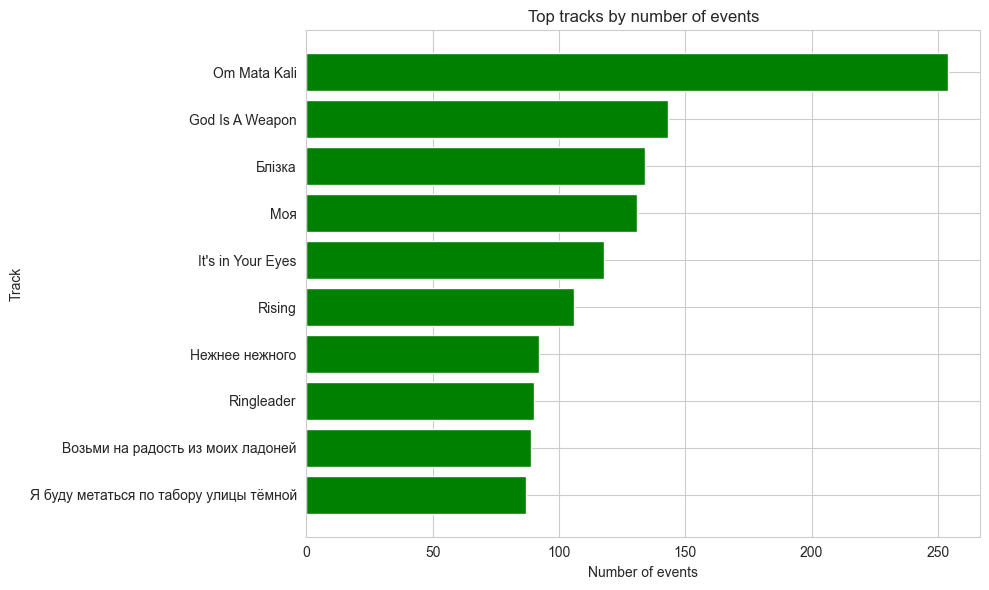

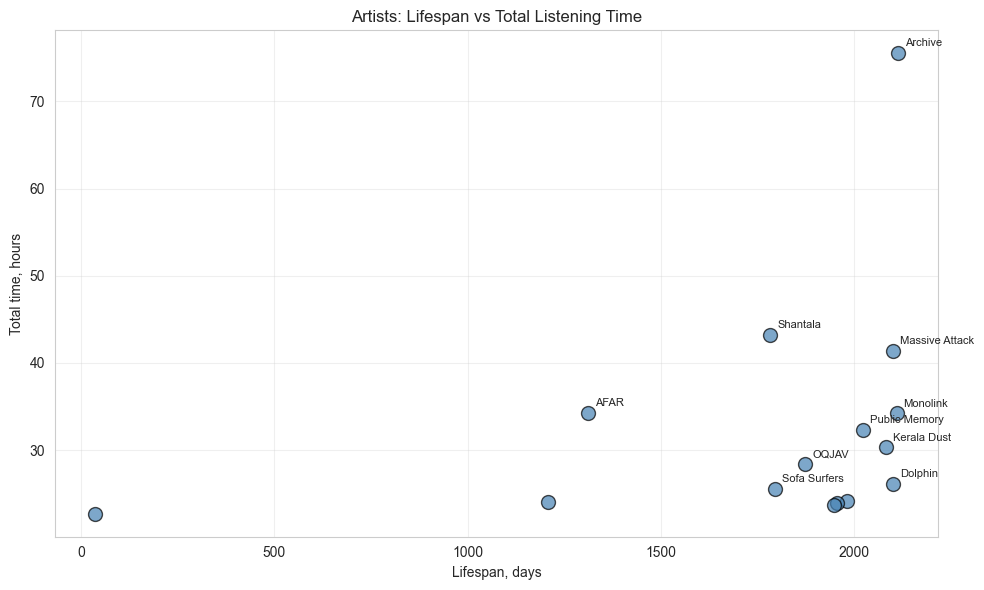

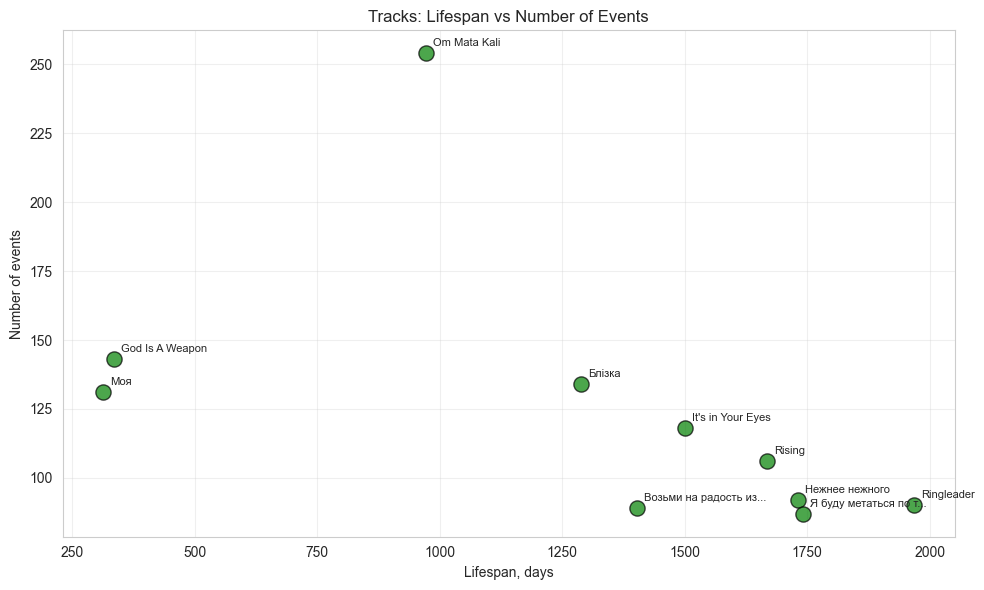

📊 Top artists by total listening time:


,Artist,Events,Unique tracks,Events per track,Total hours,"Lifespan, days"
№,,,,,,
1,Archive,1089,275,4.0,75.5,2114
2,Shantala,300,14,21.4,43.2,1783
3,Massive Attack,604,67,9.0,41.4,2102
4,AFAR,523,61,8.6,34.3,1311
5,Monolink,513,75,6.8,34.2,2110
6,Public Memory,634,61,10.4,32.3,2023
7,Kerala Dust,452,75,6.0,30.3,2082
8,OQJAV,757,70,10.8,28.4,1874
9,Dolphin,491,75,6.5,26.1,2102



📊 Top artists by concentration (≥5 tracks):


,Artist,Events,Unique tracks,Events per track,Total hours,"Lifespan, days"
№,,,,,,
1,Shantala,300,14,21.4,43.2,1783
2,Mareux,110,6,18.3,6.0,831
3,Nomine,193,13,14.8,8.0,500
4,Boy Harsher,78,6,13.0,5.7,1666
5,PaulWetz,176,14,12.6,6.6,1627
6,Nizkiz,213,17,12.5,11.1,1531
7,Monoplay,343,28,12.2,22.0,1927
8,L.A. Rose,95,8,11.9,4.0,1437
9,ORI,177,15,11.8,5.2,1652



📊 Top albums by total listening time:


,Album,Events,Unique tracks,Events per track,Total hours
№,,,,,
1,The Love Window,258,5,51.6,40.7
2,Сохрани мою речь навсегда,711,21,33.9,26.7
3,Octopus,265,9,29.4,17.4
4,Созерцание,280,17,16.5,12.4
5,Glass Minds,125,15,8.3,11.8
6,ПРОЩАЙ ОРУЖИЕ,183,9,20.3,11.6
7,Gnothi Seauton,250,19,13.2,11.6
8,Wuthering Drum,267,11,24.3,11.5
9,Under Darkening Skies,164,12,13.7,11.1



📊 Top albums by concentration (≥5 tracks):


,Album,Events,Unique tracks,Events per track,Total hours
№,,,,,
1,The Love Window,258,5,51.6,40.7
2,Сохрани мою речь навсегда,711,21,33.9,26.7
3,Octopus,265,9,29.4,17.4
4,Wuthering Drum,267,11,24.3,11.5
5,Blind Man,118,5,23.6,3.8
6,Кромешна,280,12,23.3,10.6
7,Bedtime,439,20,22.0,7.6
8,Apnea,103,5,20.6,5.2
9,ПРОЩАЙ ОРУЖИЕ,183,9,20.3,11.6



📊 Top tracks by number of events:


,Track,Artist,Events,Total hours,"Lifespan, days"
№,,,,,
1,Om Mata Kali,Shantala,254,40.5,973
2,God Is A Weapon,Falling In Reverse,143,7.9,335
3,Блізка,Nizkiz,134,8.3,1289
4,Моя,Dolphin,131,8.8,313
5,It's in Your Eyes,Disappeared Completely,118,5.6,1501
6,Rising,Sofa Surfers,106,4.9,1668
7,Нежнее нежного,Svidaniye,92,4.2,1731
8,Ringleader,Public Memory,90,2.9,1968
9,Возьми на радость из моих ладоней,IOWA,89,2.8,1402


In [10]:
# 3. Топы с учётом широты и глубины + Lifespan_days

# Параметры топов.
# TOP_N — сколько строк выводим в таблицах.
# TOP_PLOT — сколько полос показываем на графиках.
# MIN_UNIQUE_TRACKS — минимальный порог уникальных треков для артистов/альбомов,
#   чтобы в топ по концентрации не попали однокликковые исполнители.
TOP_N = 15
TOP_PLOT = 10
MIN_UNIQUE_TRACKS = 5

# Копируем df, чтобы не портить основной датафрейм.
# ts приводим к datetime без tz — так проще считать lifespan.
data = df.copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)

# --- Артисты ---
# events — сколько всего событий прослушивания.
# unique_tracks — сколько уникальных треков артиста слышали (широта).
# events_per_track — среднее число прослушиваний на трек (глубина).
# lifespan_days — сколько дней артист присутствовал в истории.
artist_stats = data.groupby('artist_name').agg(
    events=('ts', 'count'),
    unique_tracks=('spotify_track_uri', 'nunique'),
    total_ms=('ms_played', 'sum'),
    first_seen=('ts', 'min'),
    last_seen=('ts', 'max')
).reset_index()
artist_stats['total_hours'] = (artist_stats['total_ms'] / 3600000).round(1)
artist_stats['events_per_track'] = (artist_stats['events'] / artist_stats['unique_tracks']).round(1)
artist_stats['lifespan_days'] = (artist_stats['last_seen'] - artist_stats['first_seen']).dt.days

artist_by_time = artist_stats.sort_values('total_hours', ascending=False).head(TOP_N).copy()
artist_by_time = artist_by_time[['artist_name', 'events', 'unique_tracks', 'events_per_track', 'total_hours', 'lifespan_days']]
artist_by_time.columns = ['Artist', 'Events', 'Unique tracks', 'Events per track', 'Total hours', 'Lifespan, days']

artist_dense = artist_stats[artist_stats['unique_tracks'] >= MIN_UNIQUE_TRACKS].copy()
artist_dense = artist_dense.sort_values('events_per_track', ascending=False).head(TOP_N)
artist_dense = artist_dense[['artist_name', 'events', 'unique_tracks', 'events_per_track', 'total_hours', 'lifespan_days']]
artist_dense.columns = ['Artist', 'Events', 'Unique tracks', 'Events per track', 'Total hours', 'Lifespan, days']

# График: топ артистов по суммарному времени.
top10_artist_time = artist_by_time.head(TOP_PLOT)
plt.figure(figsize=(10, 6))
plt.barh(top10_artist_time['Artist'], top10_artist_time['Total hours'],
         color='steelblue', edgecolor='white')
plt.title('Top artists by total listening time')
plt.xlabel('Total time, hours')
plt.ylabel('Artist')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# График: топ артистов по концентрации (≥5 треков).
top10_artist_dense = artist_dense.head(TOP_PLOT)
plt.figure(figsize=(10, 6))
plt.barh(top10_artist_dense['Artist'], top10_artist_dense['Events per track'],
         color='darkorange', edgecolor='white')
plt.title('Top artists by average listens per track (≥5 tracks)')
plt.xlabel('Avg events per track')
plt.ylabel('Artist')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Альбомы ---
# Альбомы группируем только по названию, без привязки к артисту,
# поэтому lifespan_days здесь не считаем: одноимённые альбомы разных
# артистов могут смешаться, и метрика будет некорректной.
album_stats = data.groupby('album_name').agg(
    events=('ts', 'count'),
    unique_tracks=('spotify_track_uri', 'nunique'),
    total_ms=('ms_played', 'sum')
).reset_index()
album_stats['total_hours'] = (album_stats['total_ms'] / 3600000).round(1)
album_stats['events_per_track'] = (album_stats['events'] / album_stats['unique_tracks']).round(1)

album_by_time = album_stats.sort_values('total_hours', ascending=False).head(TOP_N).copy()
album_by_time = album_by_time[['album_name', 'events', 'unique_tracks', 'events_per_track', 'total_hours']]
album_by_time.columns = ['Album', 'Events', 'Unique tracks', 'Events per track', 'Total hours']

album_dense = album_stats[album_stats['unique_tracks'] >= MIN_UNIQUE_TRACKS].copy()
album_dense = album_dense.sort_values('events_per_track', ascending=False).head(TOP_N)
album_dense = album_dense[['album_name', 'events', 'unique_tracks', 'events_per_track', 'total_hours']]
album_dense.columns = ['Album', 'Events', 'Unique tracks', 'Events per track', 'Total hours']

# График: топ альбомов по суммарному времени.
top10_album_time = album_by_time.head(TOP_PLOT)
plt.figure(figsize=(10, 6))
plt.barh(top10_album_time['Album'], top10_album_time['Total hours'],
         color='teal', edgecolor='white')
plt.title('Top albums by total listening time')
plt.xlabel('Total time, hours')
plt.ylabel('Album')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# График: топ альбомов по концентрации (≥5 треков).
top10_album_dense = album_dense.head(TOP_PLOT)
plt.figure(figsize=(10, 6))
plt.barh(top10_album_dense['Album'], top10_album_dense['Events per track'],
         color='purple', edgecolor='white')
plt.title('Top albums by average listens per track (≥5 tracks)')
plt.xlabel('Avg events per track')
plt.ylabel('Album')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Треки ---
# Группируем по (track_name, artist_name), потому что одноимённые треки
# у разных артистов — это разные вещи.
track_stats = data.groupby(['track_name', 'artist_name']).agg(
    events=('ts', 'count'),
    total_ms=('ms_played', 'sum'),
    first_seen=('ts', 'min'),
    last_seen=('ts', 'max')
).reset_index()
track_stats['total_hours'] = (track_stats['total_ms'] / 3600000).round(1)
track_stats['lifespan_days'] = (track_stats['last_seen'] - track_stats['first_seen']).dt.days

track_top = track_stats.sort_values('events', ascending=False).head(TOP_PLOT).copy()
track_top = track_top[['track_name', 'artist_name', 'events', 'total_hours', 'lifespan_days']]
track_top.columns = ['Track', 'Artist', 'Events', 'Total hours', 'Lifespan, days']

# График: топ треков по событиям.
plt.figure(figsize=(10, 6))
plt.barh(track_top['Track'], track_top['Events'], color='green', edgecolor='white')
plt.title('Top tracks by number of events')
plt.xlabel('Number of events')
plt.ylabel('Track')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Scatter: lifespan vs total hours для артистов.
# Разделяет «вспышки» (левый верх — мало дней, много часов)
# и «долгожителей» (правый низ — много дней, стабильно).
plt.figure(figsize=(10, 6))
top_artist_for_scatter = artist_by_time.head(TOP_N)
plt.scatter(
    top_artist_for_scatter['Lifespan, days'],
    top_artist_for_scatter['Total hours'],
    s=100, alpha=0.7, color='steelblue', edgecolor='black'
)
for _, row in top_artist_for_scatter.head(10).iterrows():
    plt.annotate(
        row['Artist'],
        (row['Lifespan, days'], row['Total hours']),
        xytext=(5, 5), textcoords='offset points', fontsize=8
    )
plt.title('Artists: Lifespan vs Total Listening Time')
plt.xlabel('Lifespan, days')
plt.ylabel('Total time, hours')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Scatter: lifespan vs events для треков.
plt.figure(figsize=(10, 6))
top_track_for_scatter = track_top
plt.scatter(
    top_track_for_scatter['Lifespan, days'],
    top_track_for_scatter['Events'],
    s=120, alpha=0.7, color='green', edgecolor='black'
)
for _, row in top_track_for_scatter.iterrows():
    plt.annotate(
        row['Track'][:20] + '...' if len(row['Track']) > 20 else row['Track'],
        (row['Lifespan, days'], row['Events']),
        xytext=(5, 5), textcoords='offset points', fontsize=8
    )
plt.title('Tracks: Lifespan vs Number of Events')
plt.xlabel('Lifespan, days')
plt.ylabel('Number of events')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Таблицы ---
print('📊 Top artists by total listening time:')
artist_by_time_display = artist_by_time.copy()
artist_by_time_display.index = range(1, len(artist_by_time_display) + 1)
artist_by_time_display.index.name = '№'
display(artist_by_time_display)

print('\n📊 Top artists by concentration (≥5 tracks):')
artist_dense_display = artist_dense.copy()
artist_dense_display.index = range(1, len(artist_dense_display) + 1)
artist_dense_display.index.name = '№'
display(artist_dense_display)

print('\n📊 Top albums by total listening time:')
album_by_time_display = album_by_time.copy()
album_by_time_display.index = range(1, len(album_by_time_display) + 1)
album_by_time_display.index.name = '№'
display(album_by_time_display)

print('\n📊 Top albums by concentration (≥5 tracks):')
album_dense_display = album_dense.copy()
album_dense_display.index = range(1, len(album_dense_display) + 1)
album_dense_display.index.name = '№'
display(album_dense_display)

print('\n📊 Top tracks by number of events:')
track_top_display = track_top.copy()
track_top_display.index = range(1, len(track_top_display) + 1)
track_top_display.index.name = '№'
display(track_top_display)

⚠️ All events: 45.5% tracks without genre — genre conclusions limited.
📊 Top 10 genres by events:


,Genre,Events,"Share of events, %",Unique tracks
№,,,,
1,unknown,36261,45.5,11196
2,downtempo,9470,11.9,2573
3,trip hop,9286,11.6,2202
4,organic house,4193,5.3,1295
5,coldwave,4175,5.2,948
6,darkwave,3124,3.9,840
7,melodic techno,2555,3.2,754
8,melodic house,2448,3.1,737
9,witch house,2442,3.1,637



📊 Top 10 genres by unique tracks:


,Genre,Unique tracks,"Share of all unique tracks, %"
№,,,
1,unknown,11196,43.7
2,downtempo,2573,10.0
3,trip hop,2202,8.6
4,organic house,1295,5.1
5,coldwave,948,3.7
6,darkwave,840,3.3
7,post-punk,767,3.0
8,melodic techno,754,2.9
9,ambient,745,2.9


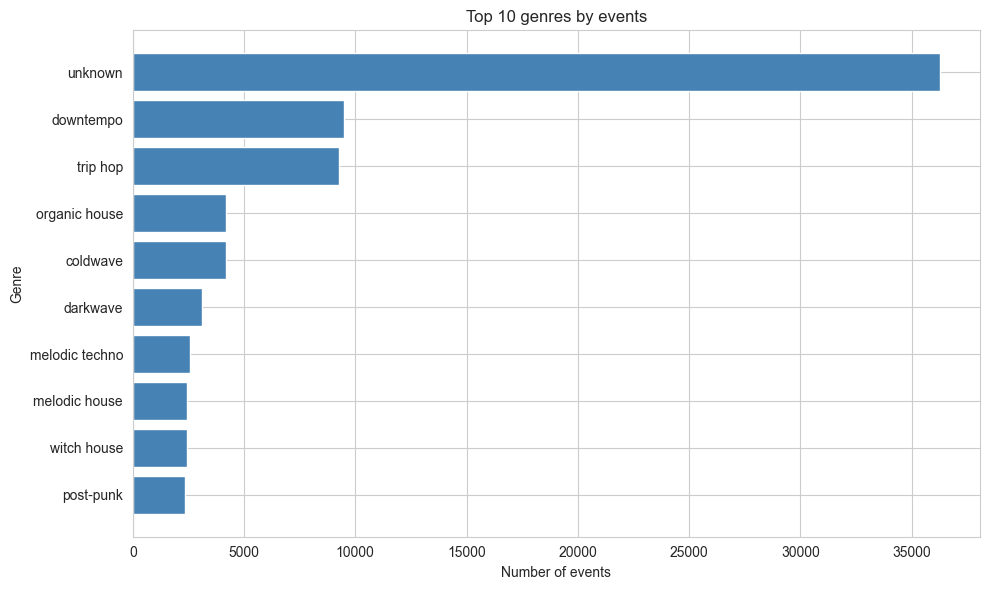

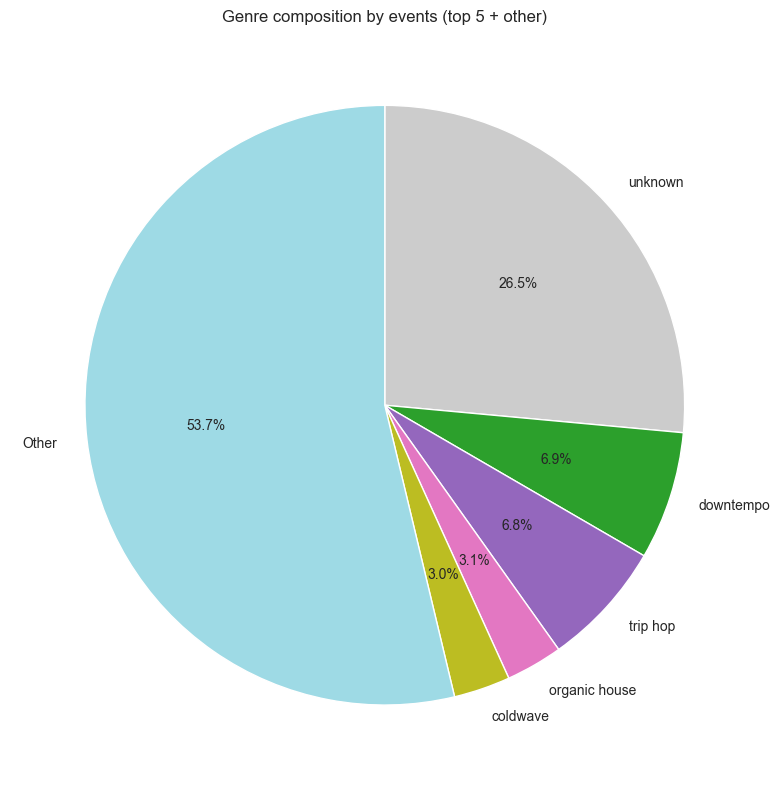

In [11]:
# 4. Жанровый профиль

# Используем готовый df из блока 0.
data = df.copy()

# 1. Проверка доли неизвестных жанров.
# Обязательный шаг перед любыми жанровыми выводами:
# если unknown >50%, жанровые выводы делать нельзя,
# если >30% — выводы ограничены.
show_unknown_share(data, 'All events')

# 2. Разворачиваем жанры.
# Один трек может иметь несколько жанров через запятую.
# explode превращает строку в отдельные записи — так мы считаем каждый жанр,
# а не только первый.
data_genre = data.copy()
data_genre['genre_list'] = data_genre['genres_normalized'].str.split(',')
data_genre = data_genre.explode('genre_list')
data_genre['genre'] = data_genre['genre_list'].str.strip()

# Распределение по событиям.
genre_event_counts = data_genre['genre'].value_counts()
genre_event_share = (genre_event_counts / len(data) * 100).round(1)

# Топ-10 жанров по событиям (включая unknown).
top10_events = genre_event_counts.head(10)
top10_events_share = (top10_events / len(data) * 100).round(1)

# Таблица: топ-10 по событиям + количество уникальных треков.
# Уникальные треки показывают широту жанра, а события — глубину.
unique_tracks_by_genre = data_genre.groupby('genre')['spotify_track_uri'].nunique()

top10_table = pd.DataFrame({
    'Genre': top10_events.index,
    'Events': top10_events.values,
    'Share of events, %': top10_events_share.values,
    'Unique tracks': [unique_tracks_by_genre.get(g, 0) for g in top10_events.index]
})
top10_table.index = range(1, len(top10_table) + 1)
top10_table.index.name = '№'
print('📊 Top 10 genres by events:')
display(top10_table)

# Распределение по уникальным трекам.
# Жанр может быть несколько у одного трека, поэтому сумма > числа треков.
genre_track_counts = data_genre.drop_duplicates(subset=['spotify_track_uri', 'genre'])['genre'].value_counts()
top10_tracks = genre_track_counts.head(10)
top10_tracks_share = (top10_tracks / data['spotify_track_uri'].nunique() * 100).round(1)

top10_tracks_table = pd.DataFrame({
    'Genre': top10_tracks.index,
    'Unique tracks': top10_tracks.values,
    'Share of all unique tracks, %': top10_tracks_share.values
})
top10_tracks_table.index = range(1, len(top10_tracks_table) + 1)
top10_tracks_table.index.name = '№'
print('\n📊 Top 10 genres by unique tracks:')
display(top10_tracks_table)

# 3. График: топ-10 по событиям.
plt.figure(figsize=(10, 6))
plt.barh(top10_events.index, top10_events.values, color='steelblue', edgecolor='white')
plt.title('Top 10 genres by events')
plt.xlabel('Number of events')
plt.ylabel('Genre')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 4. Pie chart: топ-5 + Other.
# Показывает, какая часть потока сосредоточена в голове распределения,
# а какая — в хвосте и unknown.
top5 = genre_event_counts.head(5)
other_sum = genre_event_counts.iloc[5:].sum()
pie_data = top5.copy()
if other_sum > 0:
    pie_data['Other'] = other_sum

colors = plt.cm.tab20(np.linspace(0, 1, len(pie_data)))
if 'unknown' in pie_data.index:
    idx = list(pie_data.index).index('unknown')
    colors[idx] = [0.8, 0.8, 0.8, 1]

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    pie_data.values, labels=pie_data.index, colors=colors,
    autopct='%1.1f%%', startangle=90, counterclock=False,
    wedgeprops=dict(edgecolor='white', linewidth=1),
    textprops=dict(fontsize=10)
)
ax.set_title('Genre composition by events (top 5 + other)')
plt.tight_layout()
plt.show()

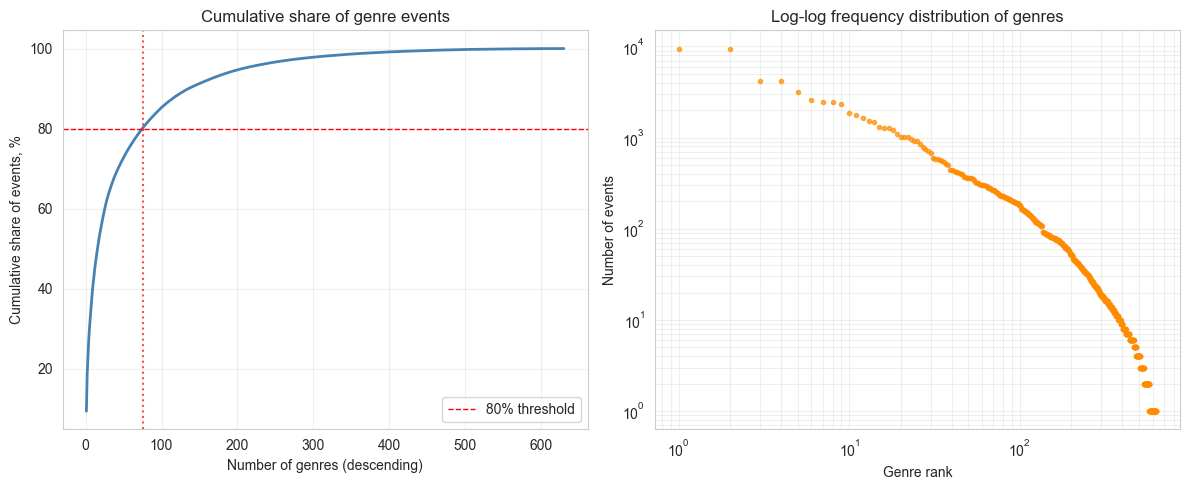

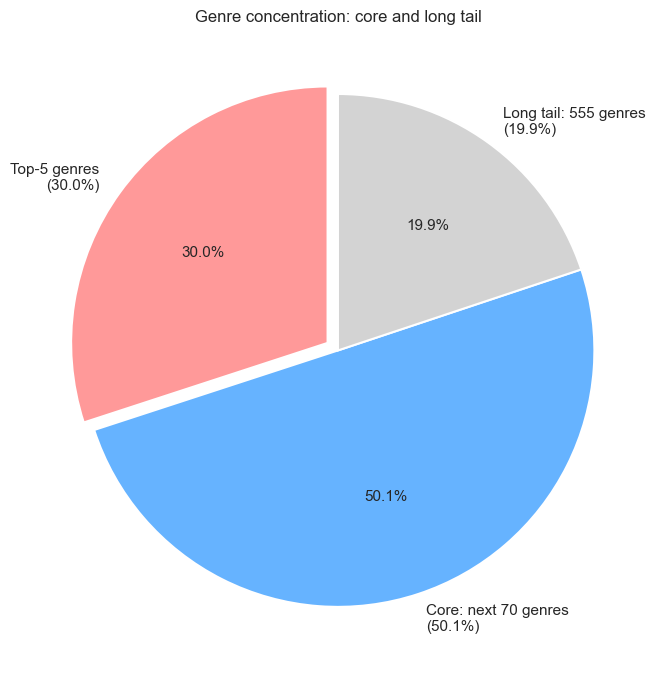

Known genres: 630
Genres covering 80% of events: 75
Long tail genres: 555
Top-5 share of events: 30.0%


In [12]:
# 4.1 Концентрация жанров: ядро и длинный хвост

# Считаем, сколько жанров покрывают 80% прослушиваний.
# Это показывает, насколько вкус сконцентрирован: если 80% дают 10 жанров —
# вкус узкий, если 200 — широкий.
# Используем известные жанры без unknown, иначе доля unknown искажает картину.
genre_series = data_genre['genre']
genre_series = genre_series[genre_series != 'unknown']

genre_event_counts = genre_series.value_counts()
total_events = len(genre_series)

# Кумулятивная доля событий по жанрам, отсортированным по убыванию частоты.
sorted_share = genre_event_counts / total_events
cum_share = sorted_share.cumsum()

# Сколько жанров покрывают 80% событий.
# +1 — потому что жанр, пересекающий порог, тоже считается.
genre_count_80 = (cum_share <= 0.80).sum() + 1

top_cum_share = cum_share.head(30) * 100

# График: кумулятивная доля + log-log хвост.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Кумулятивная доля: наглядно видно точку 80%.
ax1 = axes[0]
ax1.plot(range(1, len(cum_share) + 1), cum_share.values * 100,
         linewidth=2, color='steelblue')
ax1.axhline(80, color='red', linestyle='--', linewidth=1, label='80% threshold')
ax1.axvline(genre_count_80, color='red', linestyle=':', alpha=0.7)
ax1.set_xlabel('Number of genres (descending)')
ax1.set_ylabel('Cumulative share of events, %')
ax1.set_title('Cumulative share of genre events')
ax1.grid(True, alpha=0.3)
ax1.legend()

# 2. Log-log распределение частот.
# Прямая линия в log-log означает степенной закон — типичная картина
# для культурных данных: несколько жанров-гигантов и очень длинный хвост.
ax2 = axes[1]
freq_sorted = genre_event_counts.sort_values(ascending=False)
rank = np.arange(1, len(freq_sorted) + 1)
ax2.loglog(rank, freq_sorted.values, marker='.', linestyle='None', color='darkorange', alpha=0.7)
ax2.set_xlabel('Genre rank')
ax2.set_ylabel('Number of events')
ax2.set_title('Log-log frequency distribution of genres')
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

# Пирог концентрации: топ-5 / остальное ядро / длинный хвост.
# Показывает, как распределены события между "головой", "телом" и "хвостом".
top5_share = cum_share.iloc[4] * 100
core_rest_share = (cum_share.iloc[genre_count_80 - 1] - cum_share.iloc[4]) * 100
tail_share = (1 - cum_share.iloc[genre_count_80 - 1]) * 100

labels = [
    f'Top-5 genres\n({top5_share:.1f}%)',
    f'Core: next {genre_count_80 - 5} genres\n({core_rest_share:.1f}%)',
    f'Long tail: {len(genre_event_counts) - genre_count_80} genres\n({tail_share:.1f}%)'
]
sizes = [top5_share, core_rest_share, tail_share]
colors = ['#ff9999', '#66b3ff', '#d3d3d3']
explode = (0.05, 0, 0)

plt.figure(figsize=(7, 7))
plt.pie(
    sizes,
    labels=labels,
    colors=colors,
    explode=explode,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=11)
)
plt.title('Genre concentration: core and long tail')
plt.tight_layout()
plt.show()

# --- Сводка ---
# known_genres — сколько жанров встретилось хоть раз (без unknown).
# core_genres — сколько жанров покрывают 80% событий.
# tail_genres — сколько жанров в длинном хвосте (по 20% событий суммарно).
print(f'Known genres: {len(genre_event_counts)}')
print(f'Genres covering 80% of events: {genre_count_80}')
print(f'Long tail genres: {len(genre_event_counts) - genre_count_80}')
print(f'Top-5 share of events: {cum_share.iloc[4]*100:.1f}%')

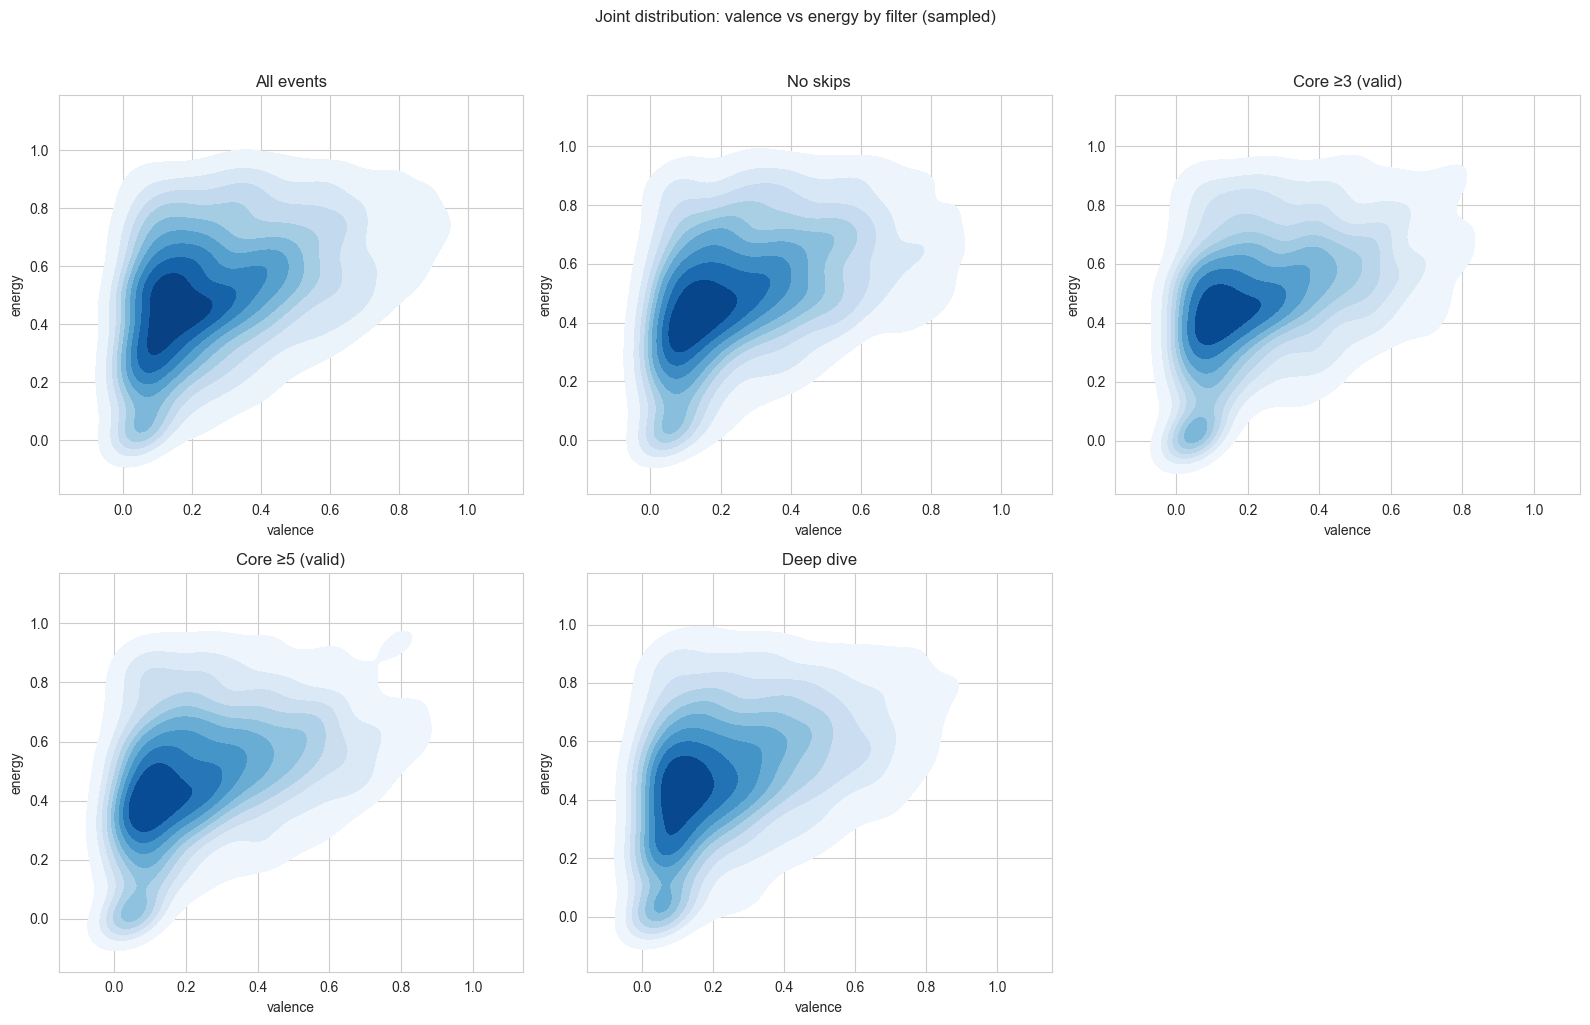

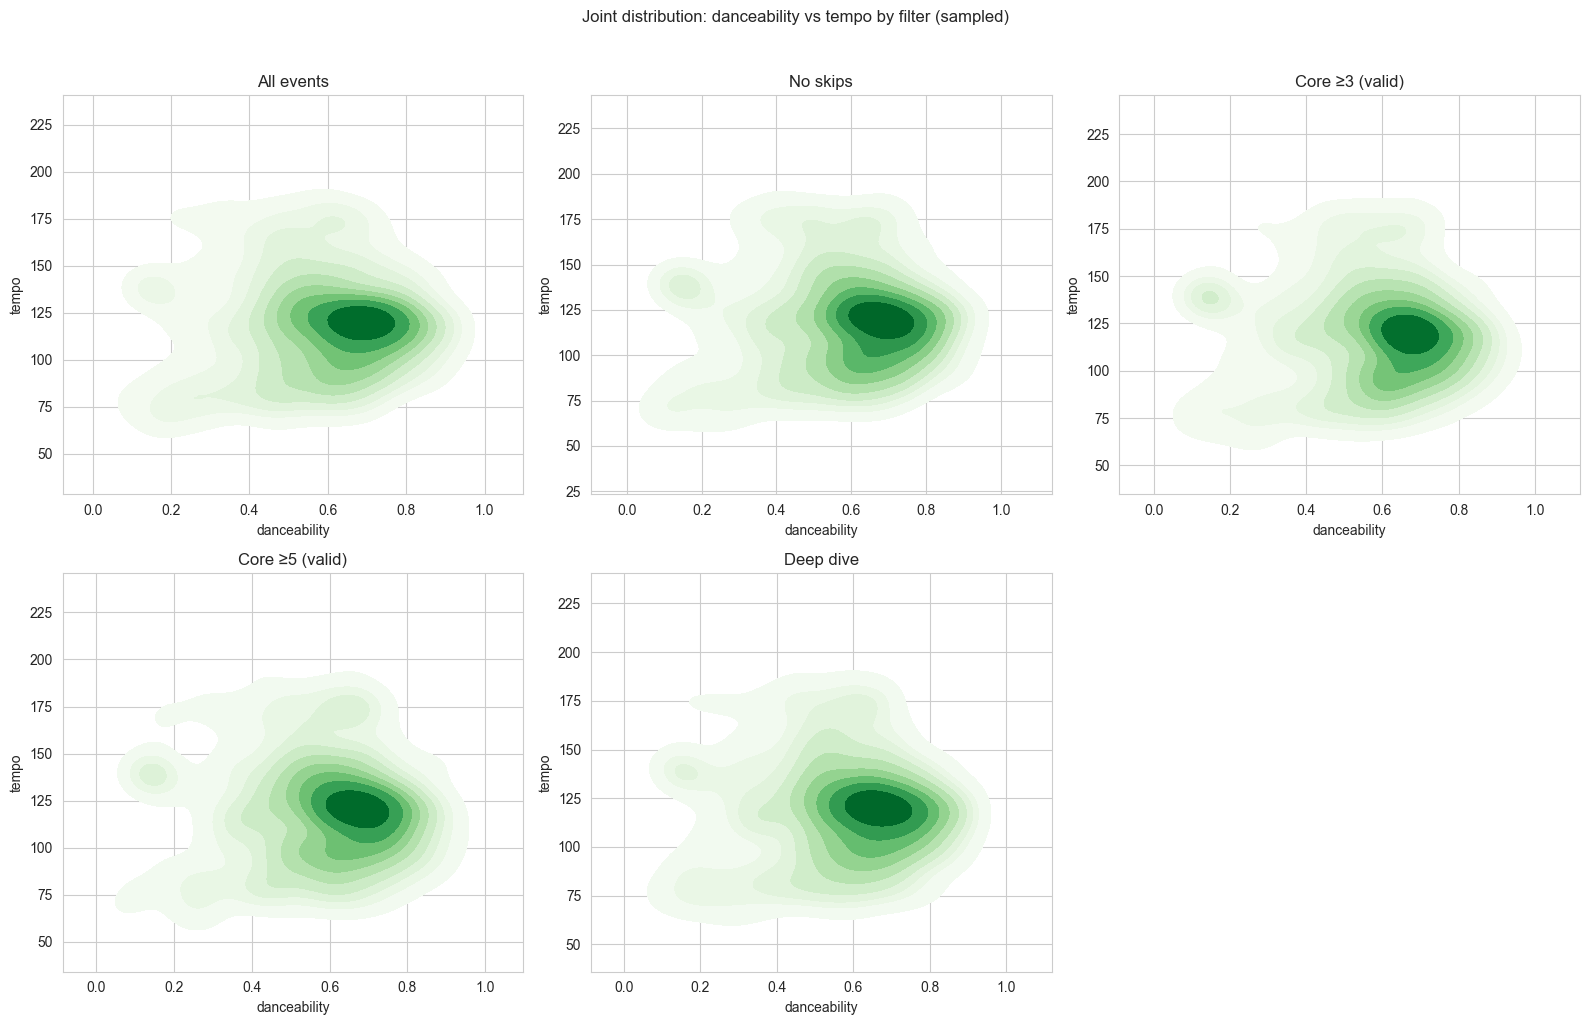

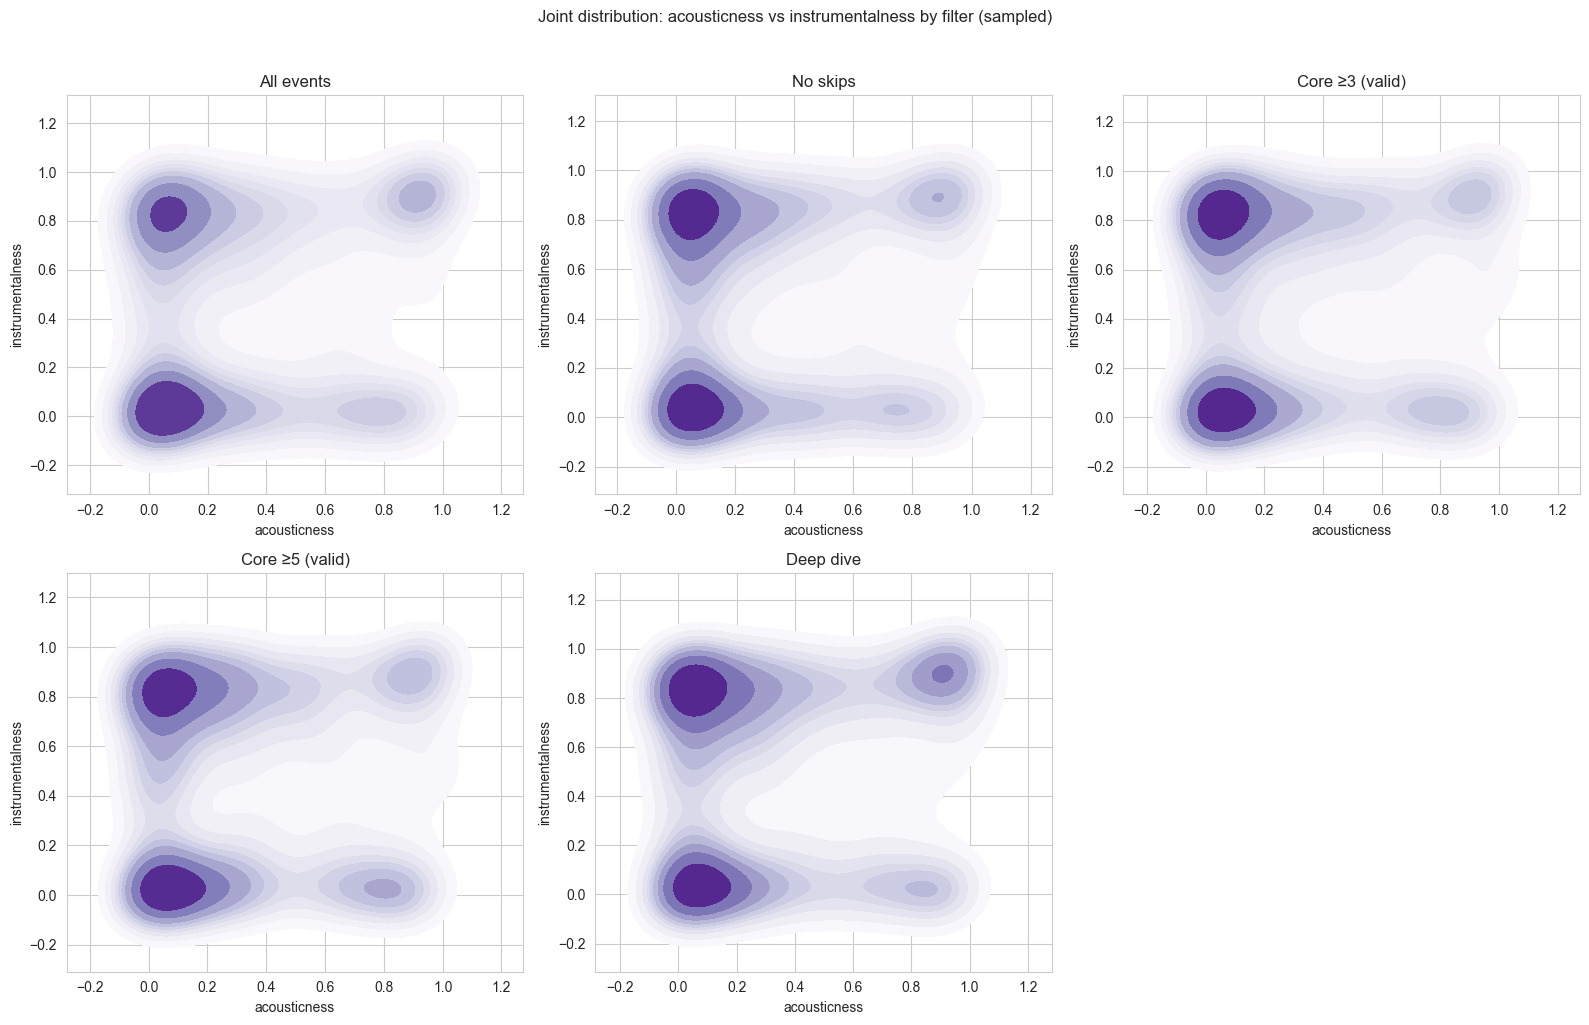

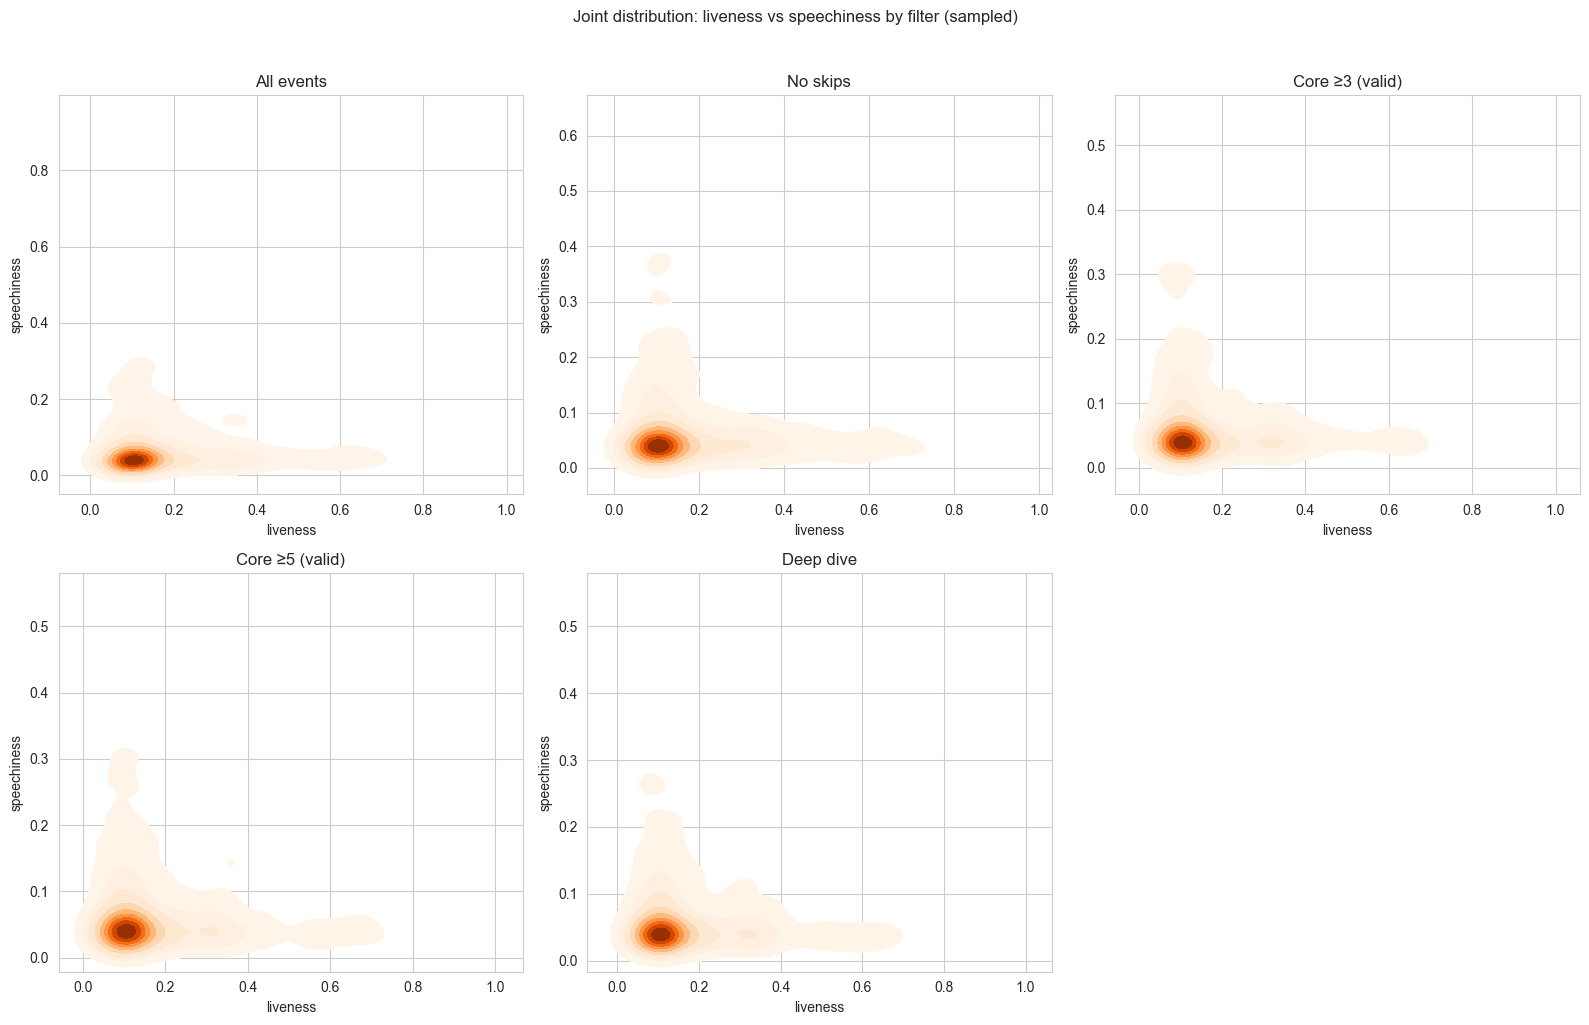

In [13]:
# 5.1 Визуализация: двумерные KDE по парам характеристик

# Смотрим совместные распределения пар характеристик по каждому фильтру.
# Цель — увидеть, меняется ли форма «облака» в зависимости от фильтра,
# а не только средние. Если облака совпадают — фильтры не создают разных
# звуковых профилей.
#
# SAMPLE_SIZE — размер случайной подвыборки для KDE. Двумерный KDE
# тяжёлый при десятках тысяч точек, сэмплирование ускоряет построение
# без потери визуальной картины.
SAMPLE_SIZE = 2000
RANDOM_STATE = 42

pairs = [
    ('valence', 'energy'),
    ('danceability', 'tempo'),
    ('acousticness', 'instrumentalness'),
    ('liveness', 'speechiness'),
]

cmaps = {
    ('valence', 'energy'): 'Blues',
    ('danceability', 'tempo'): 'Greens',
    ('acousticness', 'instrumentalness'): 'Purples',
    ('liveness', 'speechiness'): 'Oranges',
}

# Для каждой пары — small multiples: одна ячейка на фильтр.
for pair in pairs:
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()

    for i, (name, mask) in enumerate(filters.items()):
        subset = df[mask][[pair[0], pair[1]]].dropna()
        if len(subset) > SAMPLE_SIZE:
            subset = subset.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

        if len(subset) > 0:
            sns.kdeplot(
                data=subset, x=pair[0], y=pair[1],
                fill=True, cmap=cmaps[pair], ax=axes[i], warn_singular=False
            )
        axes[i].set_title(name)
        axes[i].set_xlabel(pair[0])
        axes[i].set_ylabel(pair[1])

    # Скрываем неиспользованные ячейки (их 6, а фильтров 5).
    for j in range(len(filters), len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'Joint distribution: {pair[0]} vs {pair[1]} by filter (sampled)', y=1.02)
    plt.tight_layout()
    plt.show()

In [18]:
# 5.2 Средние, медианы и статистическая значимость

# Сравниваем аудио-характеристики по фильтрам двумя способами:
#   - средние и медианы — показывают центральную тенденцию;
#   - критерий Краскела–Уоллиса — проверяет, есть ли различия вообще.
#
# Важно: фильтры вложены (All events ⊃ No skips ⊃ Core ≥3 ⊃ Core ≥5,
# а Deep dive частично пересекается с ядром), поэтому выборки не являются
# независимыми. p-value Краскела–Уоллиса здесь — ориентир, а не строгая
# проверка гипотезы. Решающий критерий — разброс средних относительно порога.

from scipy import stats

features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']

# Пороги практической существенности.
# Для долей [0,1] — 0.02, для tempo — 2 BPM, для loudness — 1 дБ,
# для popularity — 5 пунктов. Значения взяты из STYLE_GUIDE.
thresholds = {
    'valence': 0.02,
    'energy': 0.02,
    'danceability': 0.02,
    'acousticness': 0.02,
    'instrumentalness': 0.02,
    'tempo': 2.0,
    'loudness': 1.0,
    'popularity': 5.0,
}

# Средние и медианы по каждому фильтру.
mean_df = pd.DataFrame({
    name: {feat: round(df.loc[mask, feat].mean(), 3) for feat in features}
    for name, mask in filters.items()
}).T
median_df = pd.DataFrame({
    name: {feat: round(df.loc[mask, feat].median(), 3) for feat in features}
    for name, mask in filters.items()
}).T

print('📊 Mean audio features by filter:')
display(mean_df)
print('\n📊 Median audio features by filter:')
display(median_df)

# Статистическая значимость + практическая существенность.
# Kruskal–Wallis — непараметрический тест, не требует нормальности.
# Разброс средних (max − min) сравниваем с порогом.
print('\n📊 Significance and practical relevance:')
rows = []
for feat in features:
    group_values = [df.loc[mask, feat].dropna() for name, mask in filters.items() if len(df.loc[mask, feat].dropna()) > 0]
    if len(group_values) < 2:
        continue

    h, p = stats.kruskal(*group_values)
    max_mean = mean_df[feat].max()
    min_mean = mean_df[feat].min()
    spread = max_mean - min_mean

    statistically_significant = p < 0.05
    practically_significant = spread >= thresholds[feat]

    rows.append({
        'Feature': feat,
        'p-value': p,
        'Stat. significant': 'yes' if statistically_significant else 'no',
        'Mean spread': round(spread, 3),
        'Threshold': thresholds[feat],
        'Practically significant': 'yes' if practically_significant else 'no',
    })

sig_df = pd.DataFrame(rows)
sig_df.index = range(1, len(sig_df) + 1)
sig_df.index.name = '№'
display(sig_df)

📊 Mean audio features by filter:


,valence,energy,danceability,acousticness,instrumentalness,tempo,loudness,popularity
All events,0.295,0.508,0.575,0.358,0.440,119.185,-11.335,33.113
No skips,0.281,0.497,0.573,0.365,0.467,118.960,-11.670,32.552
Core ≥3 (valid),0.273,0.491,0.576,0.363,0.466,119.039,-11.757,33.892
Core ≥5 (valid),0.275,0.491,0.579,0.359,0.457,119.286,-11.641,34.250
Deep dive,0.276,0.491,0.571,0.369,0.482,118.914,-11.854,32.712



📊 Median audio features by filter:


,valence,energy,danceability,acousticness,instrumentalness,tempo,loudness,popularity
All events,0.244,0.513,0.604,0.254,0.466,119.959,-10.183,34.0
No skips,0.233,0.502,0.606,0.264,0.534,119.963,-10.364,34.0
Core ≥3 (valid),0.228,0.495,0.611,0.266,0.532,119.971,-10.426,35.0
Core ≥5 (valid),0.231,0.495,0.613,0.260,0.513,119.976,-10.408,36.0
Deep dive,0.228,0.496,0.606,0.271,0.569,119.965,-10.467,34.0



📊 Significance and practical relevance:


,Feature,p-value,Stat. significant,Mean spread,Threshold,Practically significant
№,,,,,,
1,valence,2.466543e-65,yes,0.022,0.02,yes
2,energy,1.609602e-49,yes,0.017,0.02,no
3,danceability,1.246959e-07,yes,0.008,0.02,no
4,acousticness,8.983597e-09,yes,0.011,0.02,no
5,instrumentalness,7.402520e-97,yes,0.042,0.02,yes
6,tempo,3.928403e-01,no,0.372,2.00,no
7,loudness,4.169127e-55,yes,0.519,1.00,no
8,popularity,4.593990e-56,yes,1.698,5.00,no


📊 Explicit share by filter:


,Filter,N,"Explicit share, %"
№,,,
1,All events,79752,5.2
2,No skips,51745,4.5
3,Core ≥3 (valid),32058,4.6
4,Core ≥5 (valid),26102,5.0
5,Deep dive,45620,4.3


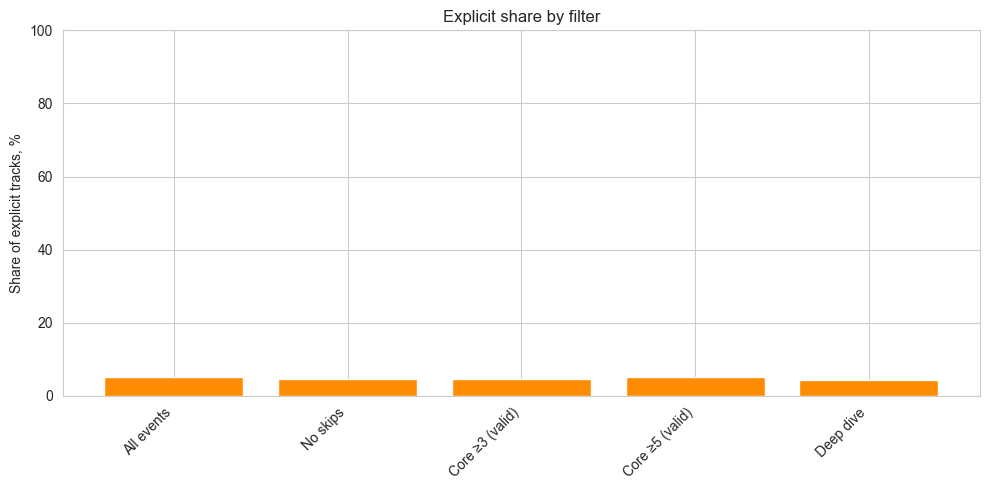


📊 Mode distribution by filter:


,Filter,N,"Minor (0), %","Major (1), %"
№,,,,
1,All events,79745,54.6,45.4
2,No skips,51743,55.5,44.5
3,Core ≥3 (valid),32058,56.4,43.6
4,Core ≥5 (valid),26102,56.3,43.7
5,Deep dive,45618,55.5,44.5



📊 Key distribution (All events):


,Key,Events,"Share, %"
№,,,
1,0.0,8209,10.3
2,1.0,7042,8.8
3,2.0,7846,9.8
4,3.0,2273,2.9
5,4.0,6951,8.7
6,5.0,6813,8.5
7,6.0,5417,6.8
8,7.0,8967,11.2
9,8.0,4962,6.2


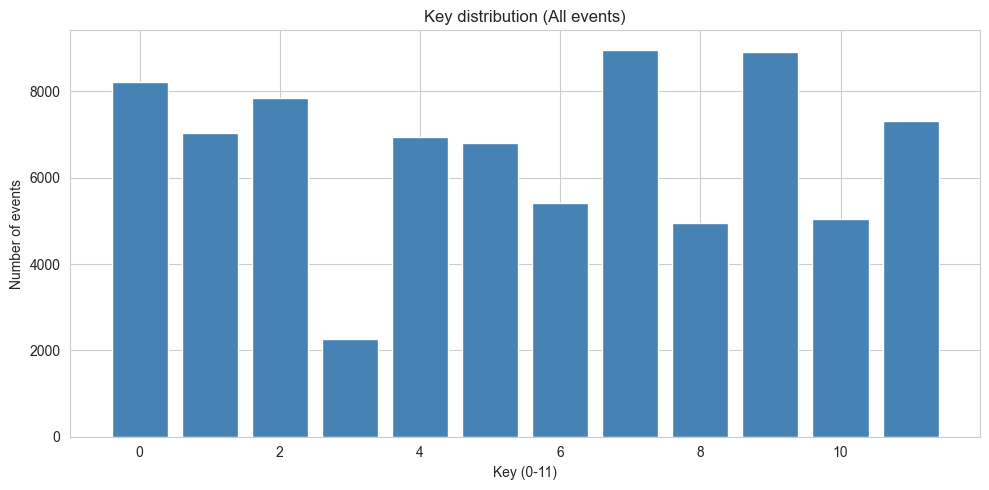


📊 Top-10 key-mode pairs in Deep dive (%):


,Key-mode,"Deep dive, %"
№,,
1,9-minor,7.6
2,11-minor,7.3
3,4-minor,7.1
4,7-major,6.8
5,0-major,6.6
6,2-major,5.6
7,1-major,5.5
8,5-minor,5.1
9,10-minor,4.8



📊 Release year stats by filter:


,Filter,N,Median year,Min year,Max year
№,,,,,
1,All events,77925,2020,1921,2026
2,No skips,50656,2020,1921,2026
3,Core ≥3 (valid),31333,2020,1964,2026
4,Core ≥5 (valid),25529,2020,1965,2026
5,Deep dive,44656,2020,1921,2026



📊 Release year distribution (1960–2026):


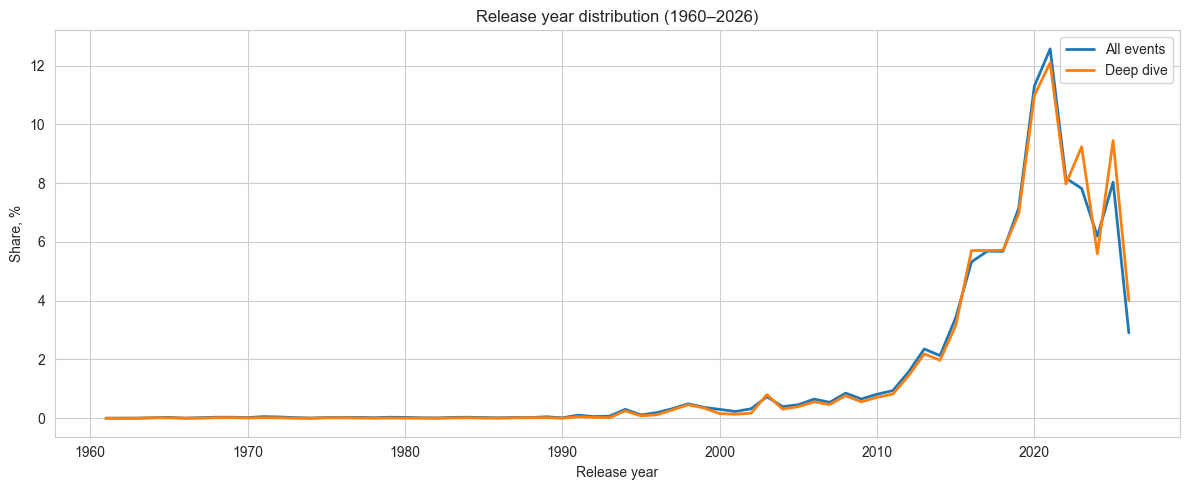


📊 Events by release decade:


,Decade,All events,No skips,Core ≥3 (valid),Core ≥5 (valid),Deep dive
№,,,,,,
1,1920s,1,1,0,0,1
2,1950s,17,9,0,0,7
3,1960s,123,42,21,17,37
4,1970s,227,67,24,16,46
5,1980s,212,56,14,11,37
6,1990s,1603,875,458,348,742
7,2000s,4018,2274,1326,1060,1939
8,2010s,27325,17707,10810,8864,15352
9,2020s,44399,29625,18680,15213,26495



📊 Unique tracks by release decade:


,Decade,All events,No skips,Core ≥3 (valid),Core ≥5 (valid),Deep dive
№,,,,,,
1,1920s,1,1,0,0,1
2,1950s,13,6,0,0,5
3,1960s,70,19,4,3,17
4,1970s,132,35,5,3,22
5,1980s,153,36,3,2,23
6,1990s,613,344,69,37,286
7,2000s,1527,840,170,91,677
8,2010s,8244,5817,1385,806,5102
9,2020s,14249,9890,2425,1388,8854


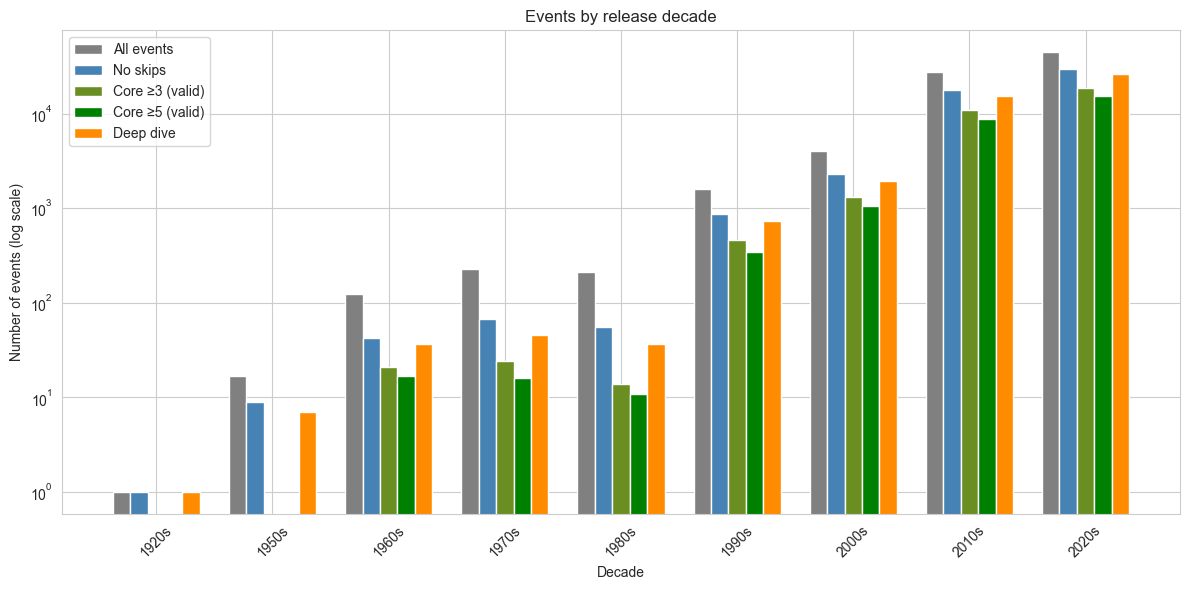


🔍 Median release year: All events — 2020, Deep dive — 2020.


In [19]:
# 6. Дополнительные параметры: explicit, mode, key_mode, release_date

# Блок отвечает на вопросы:
#   explicit    — есть ли ненормативная лексика;
#   mode        — минор vs мажор;
#   key         — распределение тональностей;
#   key_mode    — топ комбинаций «тональность + лад» в Deep dive;
#   release_*   — насколько музыка современна.
#
# Здесь нет проверки статистической значимости. Это описательный блок:
# при таких выборках любое различие будет значимым (см. 5.2), поэтому
# важна величина разницы, а не p-value.

if 'filters' not in globals() or 'df' not in globals():
    raise ValueError('Переменные df и filters не найдены. Сначала выполните блок 0.')

# Цвета для графиков по фильтрам — единые для всего блока.
filter_colors = {
    'All events':      'gray',
    'No skips':        'steelblue',
    'Core ≥3 (valid)': 'olivedrab',
    'Core ≥5 (valid)': 'green',
    'Deep dive':       'darkorange',
}

# ---------- 1. Explicit ----------
# Доля явного контента. Смотрим, отличается ли она в осознанных фильтрах
# от общего потока — это может показать, избегает ли пользователь
# эксплицитной музыки в глубоком прослушивании.
print('📊 Explicit share by filter:')
explicit_rows = []
for name, mask in filters.items():
    subset = df[mask]
    if 'explicit' in subset.columns:
        explicit_share = subset['explicit'].mean() * 100
    else:
        explicit_share = np.nan
    explicit_rows.append({
        'Filter': name,
        'N': len(subset),
        'Explicit share, %': round(explicit_share, 1)
    })
explicit_df = pd.DataFrame(explicit_rows)
explicit_df.index = range(1, len(explicit_df) + 1)
explicit_df.index.name = '№'
display(explicit_df)

plt.figure(figsize=(10, 5))
plt.bar(explicit_df['Filter'], explicit_df['Explicit share, %'],
        color='darkorange', edgecolor='white')
plt.title('Explicit share by filter')
plt.ylabel('Share of explicit tracks, %')
plt.ylim(0, 100)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ---------- 2. Mode (minor vs major) ----------
# Распределение лада. Минор = 0, мажор = 1.
# Смотрим, отличается ли доля минора в ядре от общего потока:
# если да, это подтверждает меланхоличный профиль.
print('\n📊 Mode distribution by filter:')
mode_rows = []
for name, mask in filters.items():
    subset = df[mask].dropna(subset=['mode'])
    total = len(subset)
    if total == 0:
        continue
    mode_counts = subset['mode'].value_counts().sort_index()
    minor_pct = mode_counts.get(0, 0) / total * 100
    major_pct = mode_counts.get(1, 0) / total * 100
    mode_rows.append({
        'Filter': name,
        'N': total,
        'Minor (0), %': round(minor_pct, 1),
        'Major (1), %': round(major_pct, 1),
    })
mode_df = pd.DataFrame(mode_rows)
mode_df.index = range(1, len(mode_df) + 1)
mode_df.index.name = '№'
display(mode_df)

# ---------- 3. Key distribution ----------
# Распределение тональностей по всем событиям.
# key — это целое число от 0 до 11 (соответствие нотам фиксировано Spotify).
print('\n📊 Key distribution (All events):')
key_counts = df['key'].value_counts().sort_index()
key_df = pd.DataFrame({
    'Key': key_counts.index,
    'Events': key_counts.values,
    'Share, %': (key_counts / len(df) * 100).round(1)
})
key_df.index = range(1, len(key_df) + 1)
key_df.index.name = '№'
display(key_df)

plt.figure(figsize=(10, 5))
plt.bar(key_df['Key'], key_df['Events'], color='steelblue', edgecolor='white')
plt.title('Key distribution (All events)')
plt.xlabel('Key (0-11)')
plt.ylabel('Number of events')
plt.tight_layout()
plt.show()

# ---------- 4. Top-10 key_mode by share in Deep dive ----------
# Комбинация «тональность + лад». Смотрим, какие пары чаще всего
# попадают в глубокое прослушивание.
print('\n📊 Top-10 key-mode pairs in Deep dive (%):')
deep_mask = filters['Deep dive']
valid_key_mode = df[deep_mask].dropna(subset=['key', 'mode']).copy()
valid_key_mode['key_mode'] = (
    valid_key_mode['key'].astype(int).astype(str) + '-' +
    valid_key_mode['mode'].map({0: 'minor', 1: 'major'})
)

# Перечисляем все возможные пары, чтобы в топ не попали только те,
# что случайно набрали массу. Остальные получат 0 и не попадут в топ-10.
all_pairs = [f'{k}-minor' for k in range(12)] + [f'{k}-major' for k in range(12)]
pair_counts = valid_key_mode['key_mode'].value_counts(normalize=True).reindex(all_pairs, fill_value=0) * 100
pair_counts_sorted = pair_counts.sort_values(ascending=False).head(10)

pair_summary_df = pd.DataFrame({
    'Key-mode': pair_counts_sorted.index,
    'Deep dive, %': pair_counts_sorted.values.round(1)
})
pair_summary_df.index = range(1, len(pair_summary_df) + 1)
pair_summary_df.index.name = '№'
display(pair_summary_df)

# ---------- 5. Release date ----------
# release_year и release_decade создаём здесь, если их нет:
# в блоке 0 они не нужны, а в других блоках не используются.
if 'release_year' not in df.columns:
    df['release_year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year
if 'release_decade' not in df.columns:
    df['release_decade'] = (df['release_year'] // 10 * 10).astype('Int64')

# Сводка по годам: медиана, минимум, максимум по каждому фильтру.
# Медианный год показывает «типичную современность» музыки.
print('\n📊 Release year stats by filter:')
release_stats = []
for name, mask in filters.items():
    subset = df[mask].dropna(subset=['release_year'])
    release_stats.append({
        'Filter': name,
        'N': int(subset['release_year'].notna().sum()),
        'Median year': int(subset['release_year'].median()) if subset['release_year'].notna().any() else None,
        'Min year': int(subset['release_year'].min()) if subset['release_year'].notna().any() else None,
        'Max year': int(subset['release_year'].max()) if subset['release_year'].notna().any() else None,
    })
release_df = pd.DataFrame(release_stats)
release_df.index = range(1, len(release_df) + 1)
release_df.index.name = '№'
display(release_df)

# Линейный график распределения годов релиза: All events vs Deep dive.
# Сравнение показывает, есть ли сдвиг в сторону более свежей музыки
# в глубоком прослушивании.
print('\n📊 Release year distribution (1960–2026):')
plt.figure(figsize=(12, 5))
for name, mask in [('All events', filters['All events']), ('Deep dive', filters['Deep dive'])]:
    subset = df[mask].dropna(subset=['release_year'])
    subset = subset[(subset['release_year'] >= 1960) & (subset['release_year'] <= 2026)]
    counts = subset['release_year'].value_counts(normalize=True).sort_index() * 100
    plt.plot(counts.index, counts.values, label=name, linewidth=2)
plt.xlabel('Release year')
plt.ylabel('Share, %')
plt.title('Release year distribution (1960–2026)')
plt.legend()
plt.tight_layout()
plt.show()

# Разбивка по десятилетиям: события и уникальные треки.
# События — сколько раз музыка каждого десятилетия звучала.
# Уникальные треки — насколько широко десятилетие представлено в каталоге.
print('\n📊 Events by release decade:')
decade_events = []
decade_tracks = []
for name, mask in filters.items():
    subset = df[mask].dropna(subset=['release_decade'])
    subset = subset[(subset['release_decade'] >= 1920) & (subset['release_decade'] <= 2020)]
    decade_events.append(pd.Series(subset['release_decade'].value_counts().sort_index(), name=name))
    decade_tracks.append(pd.Series(subset.drop_duplicates('spotify_track_uri')['release_decade'].value_counts().sort_index(), name=name))

decade_events_df = pd.concat(decade_events, axis=1).fillna(0).astype(int)
decade_events_df.index = [f'{int(d)}s' for d in decade_events_df.index]
decade_events_df_display = decade_events_df.reset_index()
decade_events_df_display.columns = ['Decade'] + list(decade_events_df.columns)
decade_events_df_display.index = range(1, len(decade_events_df_display) + 1)
decade_events_df_display.index.name = '№'
display(decade_events_df_display)

decade_tracks_df = pd.concat(decade_tracks, axis=1).fillna(0).astype(int)
decade_tracks_df.index = [f'{int(d)}s' for d in decade_tracks_df.index]
decade_tracks_df_display = decade_tracks_df.reset_index()
decade_tracks_df_display.columns = ['Decade'] + list(decade_tracks_df.columns)
decade_tracks_df_display.index = range(1, len(decade_tracks_df_display) + 1)
decade_tracks_df_display.index.name = '№'
print('\n📊 Unique tracks by release decade:')
display(decade_tracks_df_display)

# Барчарт по десятилетиям с лог-шкалой: диапазоны очень разные,
# без лога старые десятилетия просто исчезнут на фоне 2020-х.
plt.figure(figsize=(12, 6))
x = np.arange(len(decade_events_df))
width = 0.15
for i, (name, _) in enumerate(filters.items()):
    vals = decade_events_df[name].values
    plt.bar(x + (i-2)*width, vals, width, label=name,
            color=filter_colors[name], edgecolor='white')
plt.xticks(x, decade_events_df.index, rotation=45)
plt.xlabel('Decade')
plt.ylabel('Number of events (log scale)')
plt.yscale('log')
plt.title('Events by release decade')
plt.legend()
plt.tight_layout()
plt.show()

# Автоинтерпретация: сравнение медианных годов релиза.
release_year_median_all = release_df.loc[release_df['Filter'] == 'All events', 'Median year'].values[0]
release_year_median_deep = release_df.loc[release_df['Filter'] == 'Deep dive', 'Median year'].values[0]
print(f'\n🔍 Median release year: All events — {release_year_median_all}, Deep dive — {release_year_median_deep}.')

📊 Tracks with complete data for correlation: 19616


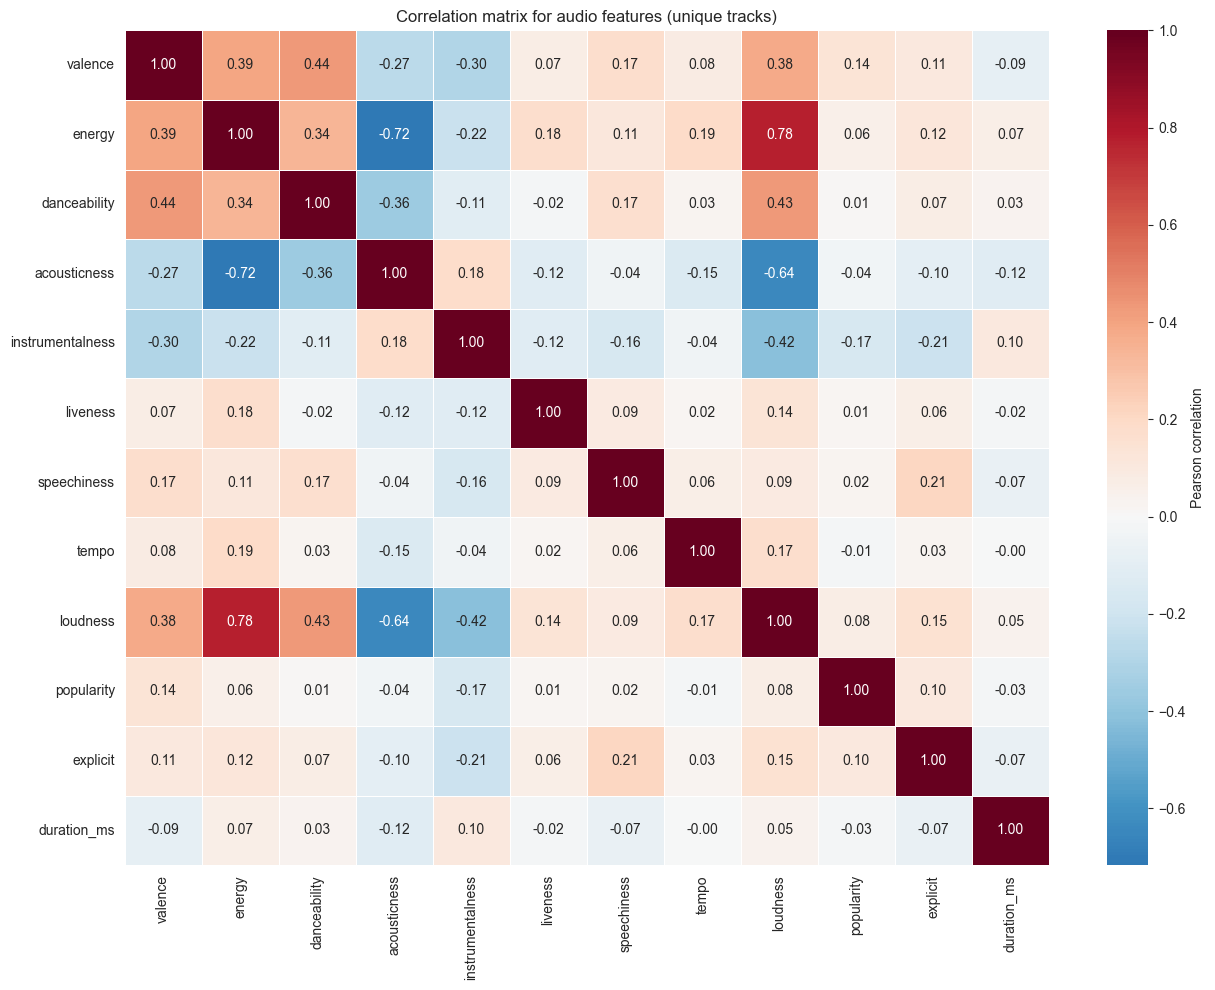


📊 Correlation matrix:


,valence,energy,danceability,acousticness,instrumentalness,liveness,speechiness,tempo,loudness,popularity,explicit,duration_ms
valence,1.00,0.39,0.44,-0.27,-0.30,0.07,0.17,0.08,0.38,0.14,0.11,-0.09
energy,0.39,1.00,0.34,-0.72,-0.22,0.18,0.11,0.19,0.78,0.06,0.12,0.07
danceability,0.44,0.34,1.00,-0.36,-0.11,-0.02,0.17,0.03,0.43,0.01,0.07,0.03
acousticness,-0.27,-0.72,-0.36,1.00,0.18,-0.12,-0.04,-0.15,-0.64,-0.04,-0.10,-0.12
instrumentalness,-0.30,-0.22,-0.11,0.18,1.00,-0.12,-0.16,-0.04,-0.42,-0.17,-0.21,0.10
liveness,0.07,0.18,-0.02,-0.12,-0.12,1.00,0.09,0.02,0.14,0.01,0.06,-0.02
speechiness,0.17,0.11,0.17,-0.04,-0.16,0.09,1.00,0.06,0.09,0.02,0.21,-0.07
tempo,0.08,0.19,0.03,-0.15,-0.04,0.02,0.06,1.00,0.17,-0.01,0.03,-0.00
loudness,0.38,0.78,0.43,-0.64,-0.42,0.14,0.09,0.17,1.00,0.08,0.15,0.05
popularity,0.14,0.06,0.01,-0.04,-0.17,0.01,0.02,-0.01,0.08,1.00,0.10,-0.03



🔺 Top-5 positive correlations:
   loudness–energy: strong positive (r=0.78, N=19616)
   danceability–valence: notable positive (r=0.44, N=19616)
   loudness–danceability: notable positive (r=0.43, N=19616)
   energy–valence: moderate positive (r=0.39, N=19616)
   loudness–valence: moderate positive (r=0.38, N=19616)

🔻 Top-5 negative correlations:
   acousticness–energy: strong negative (r=-0.72, N=19616)
   loudness–acousticness: strong negative (r=-0.64, N=19616)
   loudness–instrumentalness: notable negative (r=-0.42, N=19616)
   acousticness–danceability: moderate negative (r=-0.36, N=19616)
   instrumentalness–valence: moderate negative (r=-0.30, N=19616)

📊 Tracks: minor — 10146, major — 9470

📊 Correlation comparison: minor vs major:


,Pair,Minor (mode=0),Major (mode=1),Difference
№,,,,
1,valence × energy,0.363,0.417,-0.054
2,energy × loudness,0.763,0.793,-0.030
3,acousticness × instrumentalness,0.177,0.190,-0.013
4,danceability × tempo,-0.011,0.067,-0.078
5,valence × acousticness,-0.254,-0.292,0.039


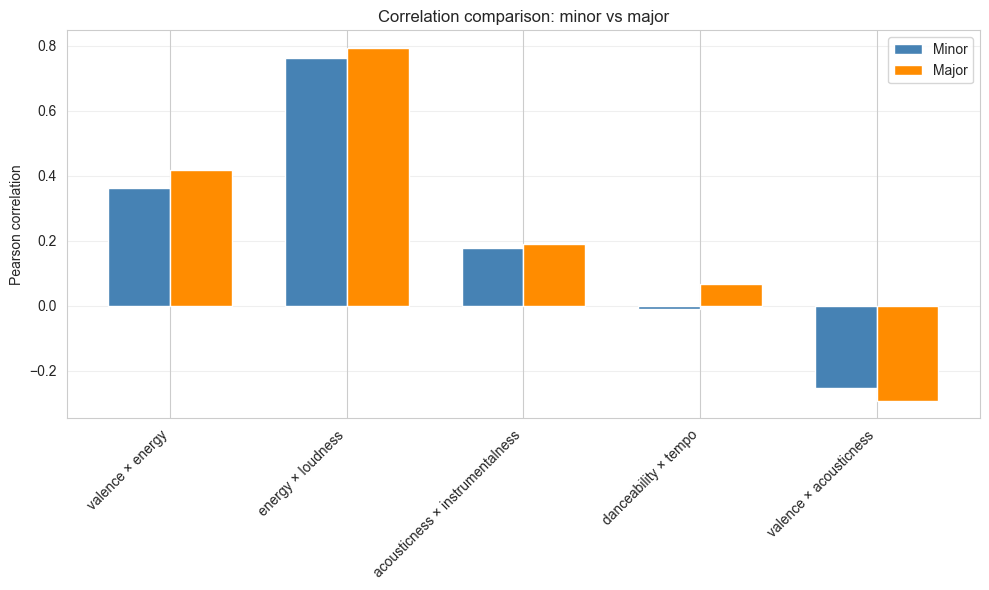


📊 Top-5 key_mode (by unique tracks): ['0-1', '9-0', '7-1', '4-0', '2-1']

📊 Mean audio features by top-5 key_mode:


,key_mode,N tracks,valence,energy,danceability,acousticness,instrumentalness,tempo,loudness
№,,,,,,,,,
1,0-1,1869,0.321,0.503,0.539,0.367,0.422,118.1,-11.87
2,9-0,1810,0.306,0.509,0.562,0.383,0.426,118.7,-11.42
3,7-1,1789,0.334,0.559,0.582,0.294,0.434,120.2,-10.62
4,4-0,1589,0.307,0.551,0.586,0.328,0.420,120.1,-10.34
5,2-1,1570,0.301,0.540,0.566,0.312,0.466,119.0,-11.15


In [20]:
# 7. Корреляционный анализ

# Смотрим, как аудио-характеристики связаны между собой.
# Это помогает увидеть единые «оси» звука: например, громкость ↔ энергия,
# акустичность ↔ энергия и так далее.
#
# Считаем по уникальным трекам, а не по событиям: частые повторы
# одних и тех же треков искажают корреляции в сторону того,
# что пользователь слушает чаще, а не того, как устроена музыка.

if 'df' not in globals():
    raise ValueError('Переменная df не найдена. Сначала выполните блок 0.')

# ----- 1. Подготовка данных -----
unique_tracks = df.drop_duplicates('spotify_track_uri').copy()

corr_features = [
    'valence', 'energy', 'danceability', 'acousticness',
    'instrumentalness', 'liveness', 'speechiness',
    'tempo', 'loudness', 'popularity', 'explicit', 'duration_ms'
]

# Оставляем только те колонки, которые есть в df.
corr_features = [c for c in corr_features if c in unique_tracks.columns]

# spotify_track_uri нужен для merge с mode, но не для корреляций.
analysis_cols = corr_features + ['spotify_track_uri']
track_features = unique_tracks[analysis_cols].dropna().copy()
if 'explicit' in track_features.columns:
    track_features['explicit'] = track_features['explicit'].astype(int)

print(f'📊 Tracks with complete data for correlation: {len(track_features)}')

corr_data = track_features[corr_features].copy()

# ----- 2. Общая корреляционная матрица -----
corr_matrix = corr_data.corr(method='pearson')

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson correlation'}
)
plt.title('Correlation matrix for audio features (unique tracks)')
plt.tight_layout()
plt.show()

print('\n📊 Correlation matrix:')
display(corr_matrix.round(2))

# ----- 3. Топ-5 положительных и отрицательных корреляций -----
# Интерпретируем силу связи и помечаем ненадёжные:
# если пар мало (N<100) или связь слабая (|r|<0.2), это помечается ⚠️.

def interpret_corr(r, n):
    abs_r = abs(r)
    if abs_r < 0.2:
        strength = 'weak'
    elif abs_r < 0.4:
        strength = 'moderate'
    elif abs_r < 0.6:
        strength = 'notable'
    else:
        strength = 'strong'
    sign = 'positive' if r > 0 else 'negative'
    reliability = ''
    if n < 100 or abs_r < 0.2:
        reliability = ' ⚠️ (unreliable/weak)'
    return f'{strength} {sign} (r={r:.2f}, N={n}){reliability}'

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_series = upper.unstack().dropna()

print('\n🔺 Top-5 positive correlations:')
for idx, val in corr_series.nlargest(5).items():
    n = corr_data[[idx[0], idx[1]]].dropna().shape[0]
    print(f'   {idx[0]}–{idx[1]}: {interpret_corr(val, n)}')

print('\n🔻 Top-5 negative correlations:')
for idx, val in corr_series.nsmallest(5).items():
    n = corr_data[[idx[0], idx[1]]].dropna().shape[0]
    print(f'   {idx[0]}–{idx[1]}: {interpret_corr(val, n)}')

# ----- 4. Сравнение корреляций в миноре и мажоре -----
# Проверяем, меняется ли внутренняя структура звука в зависимости от лада.
# Речь не о средних значениях (они похожи), а о том, как признаки связаны
# друг с другом внутри каждой подгруппы.
if 'mode' in unique_tracks.columns:
    track_features = track_features.merge(
        unique_tracks[['spotify_track_uri', 'mode']].drop_duplicates('spotify_track_uri'),
        on='spotify_track_uri', how='left'
    )

    minor_data = track_features[track_features['mode'] == 0][corr_features].copy()
    major_data = track_features[track_features['mode'] == 1][corr_features].copy()

    print(f'\n📊 Tracks: minor — {len(minor_data)}, major — {len(major_data)}')

    key_pairs = [
        ('valence', 'energy'),
        ('energy', 'loudness'),
        ('acousticness', 'instrumentalness'),
        ('danceability', 'tempo'),
        ('valence', 'acousticness'),
    ]

    comparison_rows = []
    for feat1, feat2 in key_pairs:
        corr_minor = minor_data[[feat1, feat2]].corr().iloc[0, 1]
        corr_major = major_data[[feat1, feat2]].corr().iloc[0, 1]
        comparison_rows.append({
            'Pair': f'{feat1} × {feat2}',
            'Minor (mode=0)': round(corr_minor, 3),
            'Major (mode=1)': round(corr_major, 3),
            'Difference': round(corr_minor - corr_major, 3)
        })

    comparison_df = pd.DataFrame(comparison_rows)
    comparison_df.index = range(1, len(comparison_df) + 1)
    comparison_df.index.name = '№'
    print('\n📊 Correlation comparison: minor vs major:')
    display(comparison_df)

    plt.figure(figsize=(10, 6))
    x = np.arange(len(key_pairs))
    width = 0.35
    plt.bar(x - width/2, comparison_df['Minor (mode=0)'], width, label='Minor', color='steelblue')
    plt.bar(x + width/2, comparison_df['Major (mode=1)'], width, label='Major', color='darkorange')
    plt.xticks(x, comparison_df['Pair'], rotation=45, ha='right')
    plt.ylabel('Pearson correlation')
    plt.title('Correlation comparison: minor vs major')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('\n⚠️ mode column not found, skipping minor/major comparison.')

# ----- 5. Срез по топ-5 key_mode -----
# Смотрим, отличаются ли средние аудио-характеристики у самых частых
# комбинаций «тональность + лад». Если пары отличаются — значит,
# тональность влияет на звуковой профиль.
if {'key', 'mode'}.issubset(unique_tracks.columns):
    key_mode_df = unique_tracks.dropna(subset=['key', 'mode', 'valence', 'energy']).copy()
    key_mode_df['key_mode'] = (
        key_mode_df['key'].astype(int).astype(str) + '-' +
        key_mode_df['mode'].astype(int).astype(str)
    )

    top_keymodes = key_mode_df['key_mode'].value_counts().head(5).index.tolist()
    print(f'\n📊 Top-5 key_mode (by unique tracks): {top_keymodes}')

    keymode_stats = []
    for km in top_keymodes:
        subset = key_mode_df[key_mode_df['key_mode'] == km]
        stats = {
            'key_mode': km,
            'N tracks': len(subset),
            'valence': round(subset['valence'].mean(), 3),
            'energy': round(subset['energy'].mean(), 3),
            'danceability': round(subset['danceability'].mean(), 3),
            'acousticness': round(subset['acousticness'].mean(), 3),
            'instrumentalness': round(subset['instrumentalness'].mean(), 3),
            'tempo': round(subset['tempo'].mean(), 1),
            'loudness': round(subset['loudness'].mean(), 2),
        }
        keymode_stats.append(stats)

    keymode_df = pd.DataFrame(keymode_stats)
    keymode_df.index = range(1, len(keymode_df) + 1)
    keymode_df.index.name = '№'
    print('\n📊 Mean audio features by top-5 key_mode:')
    display(keymode_df)
else:
    print('\n⚠️ key/mode columns not found, skipping key_mode slice.')

📊 Distribution summary:


,Feature,N,Min,5%,25%,Median,75%,95%,Max,IQR,Range
№,,,,,,,,,,,
1,valence,79745,0.00,0.04,0.11,0.24,0.43,0.73,0.98,0.32,0.98
2,energy,79745,0.00,0.10,0.36,0.51,0.67,0.88,1.00,0.31,1.00
3,danceability,79745,0.00,0.21,0.48,0.60,0.70,0.82,0.98,0.22,0.98
4,acousticness,79745,0.00,0.00,0.04,0.25,0.66,0.95,1.00,0.61,1.00
5,instrumentalness,79745,0.00,0.00,0.01,0.47,0.84,0.93,1.00,0.82,1.00
6,tempo,79694,33.43,77.02,100.00,119.96,134.94,173.05,241.43,34.95,208.00
7,loudness,79745,-51.56,-22.40,-12.98,-10.18,-7.92,-5.07,3.66,5.06,55.22
8,popularity,62546,1.00,4.00,19.00,34.00,45.00,64.00,95.00,26.00,94.00



📊 Extreme values (outside 1.5×IQR):


,Feature,Lower fence,Upper fence,"Extreme share, %"
№,,,,
1,valence,-0.38,0.92,0.8
2,energy,-0.10,1.12,0.0
3,danceability,0.14,1.04,1.7
4,acousticness,-0.87,1.57,0.0
5,instrumentalness,-1.22,2.07,0.0
6,tempo,47.57,187.37,1.1
7,loudness,-20.56,-0.33,6.0
8,popularity,-20.00,84.00,0.5


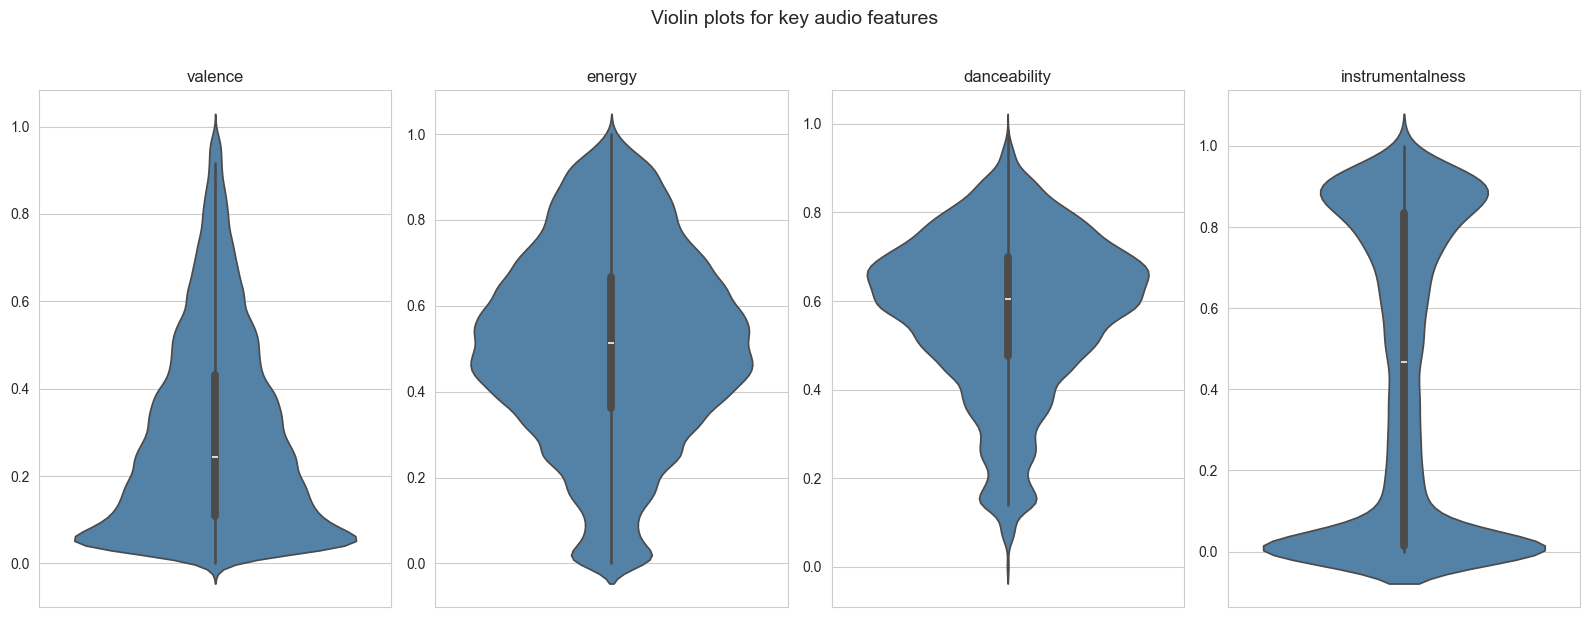


🔍 Skewness interpretation:
   • valence: median=0.24, mean=0.29, skew=0.85 → right-skewed (long right tail).
   • energy: median=0.51, mean=0.51, skew=-0.16 → almost symmetric.
   • danceability: median=0.60, mean=0.57, skew=-0.66 → left-skewed (long left tail).
   • acousticness: median=0.25, mean=0.36, skew=0.55 → right-skewed (long right tail).
   • instrumentalness: median=0.47, mean=0.44, skew=0.02 → almost symmetric.
   • tempo: median=119.96, mean=119.18, skew=0.44 → almost symmetric.
   • loudness: median=-10.18, mean=-11.34, skew=-2.30 → left-skewed (long left tail).
   • popularity: median=34.00, mean=33.11, skew=0.28 → almost symmetric.

📊 Extreme shares (Deep dive, alternative thresholds):


,Feature,Lower threshold,Upper threshold,"Share < lower, %","Share > upper, %",N
№,,,,,,
1,valence,0.1,0.9,25.3,0.7,45618
2,energy,0.2,0.8,10.8,9.1,45618
3,danceability,0.2,0.8,5.9,7.2,45618
4,acousticness,0.2,0.8,43.6,17.7,45618
5,instrumentalness,0.2,0.8,35.2,32.5,45618
6,tempo,60.0,180.0,0.3,2.2,45596
7,popularity,10.0,90.0,10.3,0.0,35914



📊 Weighted means by listening time (Deep dive):
   valence: ordinary mean 0.276, weighted mean 0.273
   energy: ordinary mean 0.491, weighted mean 0.508
   danceability: ordinary mean 0.571, weighted mean 0.583
valence: median=0.23 (range 0–1, center 0.5), IQR=[0.10, 0.40], position=left of center
energy: median=0.50 (range 0–1, center 0.5), IQR=[0.35, 0.65], position=centered
danceability: median=0.61 (range 0–1, center 0.5), IQR=[0.47, 0.70], position=right of center
acousticness: median=0.27 (range 0–1, center 0.5), IQR=[0.05, 0.67], position=left of center
instrumentalness: median=0.57 (range 0–1, center 0.5), IQR=[0.03, 0.85], position=right of center
tempo: median=119.97 (range 10–300, center 155.0), IQR=[100.00, 134.25], position=left of center
loudness: median=-10.47 (range -60–0, center -30.0), IQR=[-13.28, -8.26], position=right of center
popularity: median=34.00 (range 0–100, center 50.0), IQR=[20.00, 44.00], position=left of center


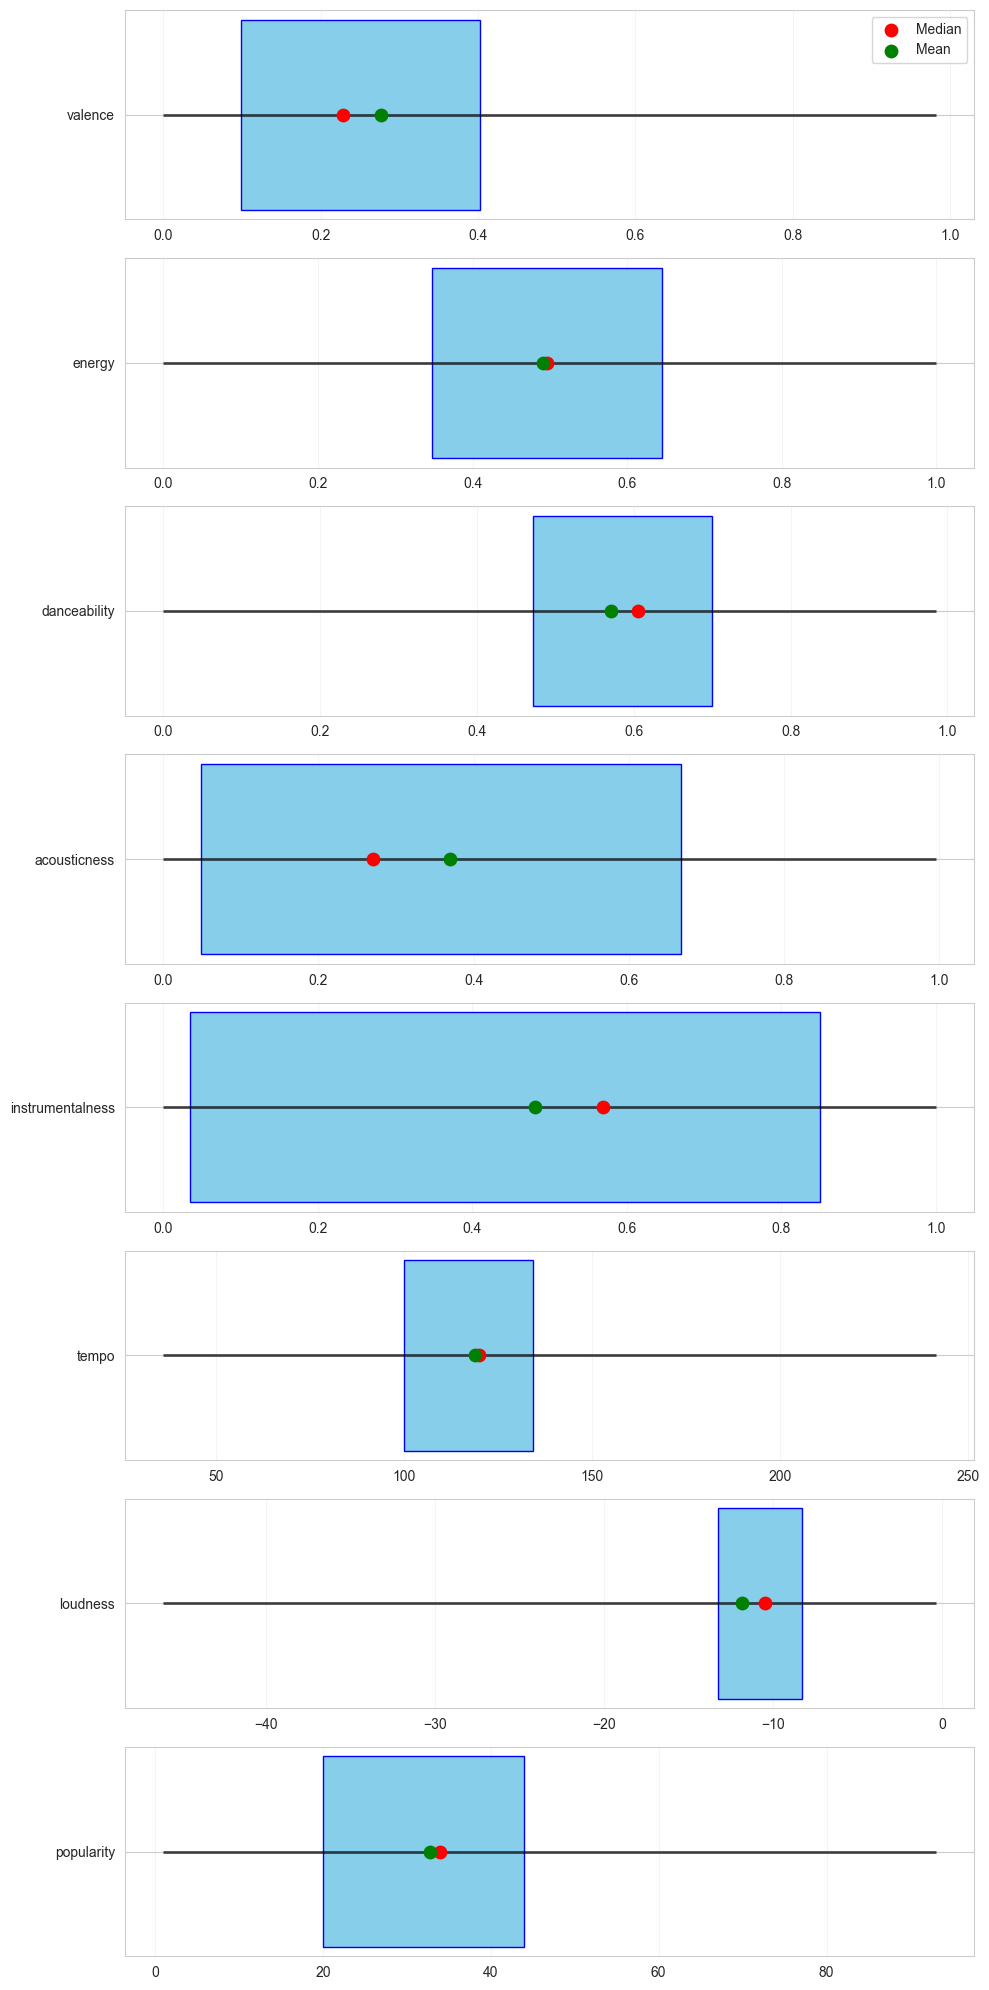

In [21]:
# 8. Экстремумы и распределения

# После средних и корреляций важно увидеть форму распределений:
# насколько они симметричны, где хвосты, есть ли выбросы.
# Это показывает, насколько вкус однороден и какие редкие зоны в нём есть.
#
# Здесь два взгляда на средние:
#   - обычное среднее (каждый трек равнозначен);
#   - взвешенное по ms_played (треки, что слушались дольше, весят больше).
# Разница между ними может выявить скрытые предпочтения.

if 'df' not in globals() or 'mask_deep' not in globals():
    raise ValueError('Переменные df и mask_deep не найдены. Сначала выполните блок 0.')

features = [
    'valence', 'energy', 'danceability', 'acousticness',
    'instrumentalness', 'tempo', 'loudness', 'popularity'
]

# ----- 1. Сводная таблица распределений (All events) -----
# Квантили 5/25/50/75/95 показывают форму распределения.
# IQR = Q75 − Q25 — устойчивая мера разброса, не чувствительная к выбросам.
# Диапазон = max − min — показывает полную ширину, но чувствителен к хвостам.
summary_rows = []
for feat in features:
    data = df[feat].dropna()
    if len(data) == 0:
        continue
    q05 = data.quantile(0.05)
    q25 = data.quantile(0.25)
    q50 = data.median()
    q75 = data.quantile(0.75)
    q95 = data.quantile(0.95)
    iqr = q75 - q25

    summary_rows.append({
        'Feature': feat,
        'N': len(data),
        'Min': round(data.min(), 2),
        '5%': round(q05, 2),
        '25%': round(q25, 2),
        'Median': round(q50, 2),
        '75%': round(q75, 2),
        '95%': round(q95, 2),
        'Max': round(data.max(), 2),
        'IQR': round(iqr, 2),
        'Range': round(data.max() - data.min(), 2),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.index = range(1, len(summary_df) + 1)
summary_df.index.name = '№'
print('📊 Distribution summary:')
display(summary_df)

# ----- 2. Доля экстремальных значений по 1.5×IQR -----
# Классическое правило Тьюки: всё, что лежит ниже Q25 − 1.5×IQR
# или выше Q75 + 1.5×IQR, считается выбросом.
print('\n📊 Extreme values (outside 1.5×IQR):')
extreme_rows = []
for feat in features:
    data = df[feat].dropna()
    if len(data) == 0:
        continue
    q25 = data.quantile(0.25)
    q75 = data.quantile(0.75)
    iqr = q75 - q25
    lower_fence = q25 - 1.5 * iqr
    upper_fence = q75 + 1.5 * iqr
    extreme_mask = (data < lower_fence) | (data > upper_fence)
    extreme_share = extreme_mask.mean() * 100
    extreme_rows.append({
        'Feature': feat,
        'Lower fence': round(lower_fence, 2),
        'Upper fence': round(upper_fence, 2),
        'Extreme share, %': round(extreme_share, 1)
    })

extreme_df = pd.DataFrame(extreme_rows)
extreme_df.index = range(1, len(extreme_df) + 1)
extreme_df.index.name = '№'
display(extreme_df)

# ----- 3. Violin plot -----
# Форма распределения лучше видна, чем через квантили:
# где плотность выше, есть ли вторая мода, есть ли хвосты.
plot_features = ['valence', 'energy', 'danceability', 'instrumentalness']
fig, axes = plt.subplots(1, 4, figsize=(16, 6))
axes = axes.flatten()

for i, feat in enumerate(plot_features):
    data = df[feat].dropna()
    sns.violinplot(y=data, ax=axes[i], color='steelblue')
    axes[i].set_title(feat)
    axes[i].set_ylabel('')

plt.suptitle('Violin plots for key audio features', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ----- 4. Автоинтерпретация асимметрии -----
# skew > 0.5 — правый хвост; < −0.5 — левый; между — почти симметрично.
# Сравнение медианы и среднего подтверждает направление хвоста.
print('\n🔍 Skewness interpretation:')
for feat in features:
    data = df[feat].dropna()
    mean = data.mean()
    median = data.median()
    skew = data.skew()
    if abs(skew) < 0.5:
        skew_desc = 'almost symmetric'
    elif skew > 0:
        skew_desc = 'right-skewed (long right tail)'
    else:
        skew_desc = 'left-skewed (long left tail)'

    print(f'   • {feat}: median={median:.2f}, mean={mean:.2f}, skew={skew:.2f} → {skew_desc}.')

# ----- 5. Альтернативные пороги экстремальности (Deep dive) -----
# 1.5×IQR — статистический критерий, но он не знает музыкального контекста.
# Здесь используем фиксированные пороги, которые имеют смысл для аудио-метрик:
#   valence < 0.1 — экстремальная меланхолия;
#   tempo < 60 или > 180 — крайне медленно или крайне быстро;
#   popularity < 10 или > 90 — нишевое или очень популярное.
deep = df[mask_deep]

thresholds = {
    'valence': (0.1, 0.9),
    'energy': (0.2, 0.8),
    'danceability': (0.2, 0.8),
    'acousticness': (0.2, 0.8),
    'instrumentalness': (0.2, 0.8),
    'tempo': (60, 180),
    'popularity': (10, 90),
}

print('\n📊 Extreme shares (Deep dive, alternative thresholds):')
extreme_deep_rows = []
for col, (low, high) in thresholds.items():
    subset = deep[col].dropna()
    low_share = (subset < low).mean() * 100
    high_share = (subset > high).mean() * 100
    extreme_deep_rows.append({
        'Feature': col,
        'Lower threshold': low,
        'Upper threshold': high,
        'Share < lower, %': round(low_share, 1),
        'Share > upper, %': round(high_share, 1),
        'N': int(subset.notna().sum()),
    })

extreme_deep_df = pd.DataFrame(extreme_deep_rows)
extreme_deep_df.index = range(1, len(extreme_deep_df) + 1)
extreme_deep_df.index.name = '№'
display(extreme_deep_df)

# Взвешенные средние по ms_played.
# Если взвешенное среднее сдвигается относительно обычного — значит,
# определённые значения характеристики удерживают пользователя дольше.
weighted_means = {}
for col in ['valence', 'energy', 'danceability']:
    subset = deep[[col, 'ms_played']].dropna()
    weighted_means[col] = (subset[col] * subset['ms_played']).sum() / subset['ms_played'].sum()

print('\n📊 Weighted means by listening time (Deep dive):')
for col, val in weighted_means.items():
    ordinary_mean = deep[col].mean()
    print(f'   {col}: ordinary mean {ordinary_mean:.3f}, weighted mean {val:.3f}')

# ----- 6. Range plot (Deep dive) -----
# Показывает сразу: min–max, IQR, медиану, среднее.
# Полезно, чтобы увидеть, где центр относительно допустимого диапазона метрики.
ranges = {
    'valence': (0, 1),
    'energy': (0, 1),
    'danceability': (0, 1),
    'acousticness': (0, 1),
    'instrumentalness': (0, 1),
    'tempo': (10, 300),
    'loudness': (-60, 0),
    'popularity': (0, 100),
}

fig, axes = plt.subplots(len(features), 1, figsize=(10, 2.5 * len(features)))

for ax, col in zip(axes, features):
    data = deep[col].dropna()
    q1, q3 = data.quantile([0.25, 0.75])
    iqr = q3 - q1
    med = data.median()
    mean = data.mean()
    min_val, max_val = data.min(), data.max()

    ax.hlines(y=col, xmin=min_val, xmax=max_val, color='black', linewidth=2, alpha=0.7)
    ax.barh(y=col, width=iqr, left=q1, height=0.4, color='skyblue', edgecolor='blue')
    ax.scatter(med, col, color='red', s=80, zorder=5, label='Median')
    ax.scatter(mean, col, color='green', s=80, zorder=5, label='Mean')

    ax.set_yticks([col])
    ax.set_yticklabels([col])
    ax.set_xlim(min_val - 0.05 * (max_val - min_val), max_val + 0.05 * (max_val - min_val))
    ax.grid(axis='x', alpha=0.2)

    low, high = ranges[col]
    midpoint = (low + high) / 2
    if med < midpoint * 0.9:
        position = 'left of center'
    elif med > midpoint * 1.1:
        position = 'right of center'
    else:
        position = 'centered'

    print(f'{col}: median={med:.2f} (range {low}–{high}, center {midpoint:.1f}), '
          f'IQR=[{q1:.2f}, {q3:.2f}], position={position}')

axes[0].legend(loc='upper right')
plt.tight_layout()
plt.show()

. Skew — это мера асимметрии. Знак skew говорит именно о хвосте: +0.85 = длинный правый хвост, −2.30 = длинный левый. Это точное описание того, что измеряет skew.

Да, для этого блока — хвост.

Потому что блок про **распределения и асимметрию**. Skew — это мера асимметрии. Знак skew говорит именно о хвосте: `+0.85` = длинный правый хвост, `−2.30` = длинный левый. Это точное описание того, что измеряет `skew`.

Формулировка эталона «смещено влево» описывает другое — **положение медианы на шкале**. У `valence` медиана 0.24 действительно ближе к 0. Но это не свойство асимметрии, а свойство шкалы [0,1]. Если бы valence измерялся от −1 до +1, медиана 0.24 была бы уже ближе к центру, а вывод «смещено влево» потерял бы смысл. А skew бы не изменился.

Поэтому:

- **skew** → хвост (right-skewed / left-skewed)
- **медиана** → положение центра (если хочется упомянуть)

Можно совместить, если важно донести оба смысла, но отдельными фразами. Например для valence:

> median=0.24, mean=0.29, skew=+0.85 → right-skewed (long right tail); median sits low on the [0,1] scale.

Так не смешиваются две разные вещи.

## Содержание `01_eda_basic.ipynb`

**Цель:** базовый музыкальный портрет — «Что слушает пользователь?».
Статический срез без временной динамики и поведения.

**Принципы:** код и комментарии по-русски, вывод и подписи графиков — по-английски. Данные — `eda_ready.parquet`, пути через `src.paths`.

---

### Ячейка 0. Setup и фильтры
Загрузка `eda_ready.parquet`, паспорт данных (объём, период, аккаунты, треки), определение `valid_play`, расчёт `valid_listen_count`, пять масок (`All events`, `No skips`, `Core ≥3`, `Core ≥5`, `Deep dive`). Определение `show_unknown_share`.

**Артефакты:** `filters`, `df` с `valid_play` и `valid_listen_count`.

---

### Ячейка 1. Масштаб и активность
Таблица масштаба по фильтрам (события / треки / артисты / альбомы / часы / дни). Средние и медианные события в день и неделю. Сравнение медианы по всем календарным дням vs только музыкальным.

**Артефакты:** нет.

---

### Ячейка 2. Access context
Офлайн vs онлайн. Единственный срез, потому что `incognito_mode` и `conn_country` удалены в `00_1` как приватные.

**Артефакты:** нет.

---

### Ячейка 3. Топы
Три подблока в одной ячейке: артисты, альбомы, треки.

- **Артисты:** события, уникальные треки (широта), события на трек (глубина), часы, lifespan.
- **Альбомы:** то же, без lifespan (группировка только по названию).
- **Треки:** события, часы, lifespan.

Графики: bar по времени, bar по концентрации, scatter lifespan vs метрика.

**Артефакты:** `artist_stats`, `album_stats`, `track_stats` и их топы.

---

### Ячейка 4. Жанровый профиль
Проверка доли `unknown`. Разворачивание жанров через `explode`. Топ-10 по событиям и по уникальным трекам. Bar chart и pie chart (топ-5 + Other).

**Артефакты:** `data_genre` с развёрнутыми жанрами.

---

### Ячейка 4.1. Концентрация жанров
Сколько жанров покрывают 80% событий. Кумулятивный график, log-log распределение, пирог «топ-5 / ядро / хвост».

**Артефакты:** нет.

---

### Ячейка 5.1. KDE по парам характеристик
Двумерные KDE для четырёх пар (`valence×energy`, `danceability×tempo`, `acousticness×instrumentalness`, `liveness×speechiness`) в small multiples по фильтрам. С сэмплированием.

**Артефакты:** нет.

---

### Ячейка 5.2. Средние, медианы, значимость
Таблицы средних и медиан по фильтрам. Kruskal–Wallis + порог практической существенности. Сноска про вложенность фильтров.

**Артефакты:** нет.

---

### Ячейка 6. Дополнительные параметры
`explicit`, `mode` (минор/мажор), `key` (тональности), `key_mode` (топ-5 в Deep dive), `release_year` / `release_decade` (современность музыки). Графики: bar, линейный по годам, bar по десятилетиям с лог-шкалой.

**Артефакты:** `release_year`, `release_decade` в `df`.

---

### Ячейка 7. Корреляции
Матрица Пирсона по уникальным трекам. Топ-5 положительных и отрицательных с автоинтерпретацией. Сравнение корреляций в миноре и мажоре. Срез по топ-5 `key_mode`.

**Артефакты:** `corr_matrix`, `track_features`.

---

### Ячейка 8. Экстремумы и распределения
Квантильная сводка. Выбросы по 1.5×IQR. Violin plot. Автоинтерпретация асимметрии (через хвост). Альтернативные пороги для Deep dive. Взвешенные средние по времени. Range plot.

**Артефакты:** нет.

---

### Итог
Ноутбук отвечает на вопрос «Что слушает пользователь?» — от масштаба до распределений. Все числа совпадают с эталоном.